> **FungiCirno production role:** this notebook trains the primary `charisis_cluster_tracking` model. It produces a TorchVision Mask R-CNN + ConvNeXt-Tiny-FPN checkpoint (`model_checkpoint.pth`), not a YOLO `.pt` checkpoint. The project app already has a matching loader. Preserve class IDs 1–3 and the labels in `class_mapping.json`; ID 0 is Mask R-CNN background.

> **Training run evidence:** the attached executed run completed 10 epochs and evaluated sequences 1 and 3. Re-run the final export cell after any metadata edit to regenerate the bundle with the canonical model key and `evaluation_metrics.json`.

---

# Charisis — Kaggle full training: cluster segmentation and tracking

**One-time setup:** add the Kaggle dataset containing the four Charisis Zenodo sequence archives as an Input to this notebook. Create that dataset once using Kaggle's **Remote Files** source and the public archive URLs listed in the [Zenodo record](https://zenodo.org/records/15041243). The notebook discovers the attached files automatically, extracts only the COCO annotation JSONs first, then extracts only the one-hour sampled image frames needed for training, validation and held-out tracking. It does not download the large source archives again.

Then select **GPU T4 x2** (the code uses one GPU), enable **Internet** for package/pretrained-weight downloads, and click **Run All**. No Drive mount or path edits are needed.

The notebook merges all four COCO annotations, trains on sequences 2 and 4, and evaluates held-out sequences 1 and 3 at the existing one-hour sampling interval. The training budget is reduced to 10 epochs, with validation-based early stopping and a runtime guard. It exports test metrics, detections, persistent cluster tracks, pixel-area growth curves, and `model_bundle.zip`.

Outputs are written to `/kaggle/working/MushroomResearch/charisis_growth_tracking`. Download `model_bundle.zip` from the notebook Output panel after the run. If a Kaggle session is interrupted, save a notebook version with outputs and attach that version's output to a new session to resume from the saved checkpoint.


## Run settings

The settings below are chosen for a free Kaggle T4 session. Training stops at the first of: 10 completed epochs, 3 consecutive validation checks without improvement, or the 7.5-hour training budget. The remaining session time is reserved for held-out inference, tracking and export.

In [6]:
RUN_MODE = 'full'  # fixed for the member run

# Charisis paper split: train sequences 2 and 4; held-out test sequences 1 and 3.
TRAIN_SEQUENCE_IDS = {2, 4}
TEST_SEQUENCE_IDS = {1, 3}
SEQUENCE_FOLDER_TO_ID = {}  # e.g. {'Timelapse_1': 1, 'Timelapse_2': 2, ...}; leave empty for automatic parsing

ZENODO_RECORD_ID = '15041243'
# Source archives must be attached through Kaggle Notebook -> Add Input.
MANUAL_DATA_ROOT = ''  # optional; leave blank to discover /kaggle/input automatically
COCO_ANNOTATION_JSON = ''  # optional exact path; auto-detected if blank

SMOKE_TRAIN_IMAGES = 8
SMOKE_TEST_IMAGES = 2
SMOKE_TRAIN_MAX_BATCHES = 2

FULL_EPOCHS = 10
EARLY_STOPPING_PATIENCE = 3
MAX_TRAINING_HOURS = 7.5
BATCH_SIZE = 1
NUM_WORKERS = 2
FULL_MIN_SIZE = 640
FULL_MAX_SIZE = 960
SMOKE_MIN_SIZE = 384
SMOKE_MAX_SIZE = 512
LEARNING_RATE = 1e-4
WEIGHT_DECAY = 1e-4
CONFIDENCE_THRESHOLD = 0.20
MASK_THRESHOLD = 0.50
MAX_MISSED_FRAMES = 3
TRACK_ACCEPTANCE_SCORE = 0.30
TRAIN_FRAME_STRIDE = 4  # 15-minute source capture -> one-hour sampling
TEST_FRAME_STRIDE = 4
MAX_TEST_IMAGES = None  # None = all held-out test images in full mode
BOX_DETECTIONS_PER_IMG = 100
TRACK_MASK_MAX_SIDE = 384
MAX_INFERENCE_SIDE = 1024
INFERENCE_SCORE_FLOOR = 0.01  # COCO AP candidate floor; project threshold is applied below


assert RUN_MODE in {'smoke', 'full'}
print('Run mode:', RUN_MODE)
print('Output root:', OUTPUT_ROOT)

Run mode: full
Output root: /kaggle/working/MushroomResearch/charisis_growth_tracking


## Install dependencies

Kaggle supplies PyTorch and TorchVision. Internet must be enabled for these small utility packages if they are not already present in the runtime.

In [4]:
%pip -q install pycocotools scipy scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [5]:
import os, sys, json, math, random, time, re, shutil, hashlib, subprocess, textwrap, zipfile, tarfile
from pathlib import Path
from datetime import datetime
from collections import defaultdict, Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw
from tqdm.auto import tqdm
import requests

import torch
import torchvision
from torch.utils.data import Dataset, DataLoader, Subset
from torchvision.transforms import functional as TF
from torchvision.models.detection import MaskRCNN
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from torchvision.models.detection.mask_rcnn import MaskRCNNPredictor
from torchvision.ops import FeaturePyramidNetwork
from torchvision.ops.feature_pyramid_network import LastLevelMaxPool
from collections import OrderedDict

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Python:', sys.version.split()[0])
print('PyTorch:', torch.__version__)
print('TorchVision:', torchvision.__version__)
print('Device:', DEVICE)
if torch.cuda.is_available():
    print('GPU:', torch.cuda.get_device_name(0))
    print('GPU memory (GiB):', round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2))
else:
    print('WARNING: No GPU found. Smoke mode may run slowly; full training is intended for a Colab GPU.')

KAGGLE_INPUT_ROOT = Path('/kaggle/input')
KAGGLE_WORK_ROOT = Path('/kaggle/working')
CACHE_ROOT = Path('/kaggle/temp/charisis_cache')
DATA_DOWNLOAD_ROOT = KAGGLE_INPUT_ROOT  # read-only attached Kaggle dataset
DATA_EXTRACT_ROOT = CACHE_ROOT / 'charisis_extracted'
OUTPUT_ROOT = KAGGLE_WORK_ROOT / 'MushroomResearch' / 'charisis_growth_tracking'
CHECKPOINT_ROOT = OUTPUT_ROOT / 'checkpoints'
RESULT_ROOT = OUTPUT_ROOT / 'results' / RUN_MODE
for p in [CACHE_ROOT, DATA_EXTRACT_ROOT, CHECKPOINT_ROOT, RESULT_ROOT]:
    p.mkdir(parents=True, exist_ok=True)
print('Kaggle input root:', KAGGLE_INPUT_ROOT)
print('Output root:', OUTPUT_ROOT)
if not KAGGLE_INPUT_ROOT.exists() or not any(KAGGLE_INPUT_ROOT.iterdir()):
    raise RuntimeError('No Kaggle Input is attached. Add the Charisis source dataset (four sequence archives) to this notebook, then Run All again.')
if RUN_MODE == 'full' and not torch.cuda.is_available():
    raise RuntimeError('No CUDA GPU detected. Select GPU T4 x2 in Notebook Settings before Run All.')

USE_AMP = (DEVICE.type == 'cuda')

# Restore training artifacts if a previous Kaggle Notebook Output was attached as an Input.
for _pattern in [
    'charisis_maskrcnn_convnext_tiny_full_last.pth',
    'charisis_maskrcnn_convnext_tiny_full_best.pth',
    'charisis_maskrcnn_convnext_tiny_full_best_validation.json',
    'training_history_full.csv',
]:
    _matches = list(KAGGLE_INPUT_ROOT.rglob(_pattern))
    for _src in _matches:
        _dst = CHECKPOINT_ROOT / _src.name if _pattern.startswith('charisis_') else RESULT_ROOT / _src.name
        if not _dst.exists():
            try:
                shutil.copy2(_src, _dst)
                print('Restored previous run artifact:', _src.name)
            except Exception as _e:
                print('Could not restore', _src, _e)


def safe_extract_zip(zip_path, destination):
    destination = Path(destination).resolve()
    destination.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(zip_path) as zf:
        for member in zf.infolist():
            target = (destination / member.filename).resolve()
            if destination not in target.parents and target != destination:
                raise RuntimeError(f'Unsafe ZIP member path: {member.filename}')
        zf.extractall(destination)


def safe_extract_tar(tar_path, destination):
    destination = Path(destination).resolve()
    destination.mkdir(parents=True, exist_ok=True)
    with tarfile.open(tar_path) as tf:
        for member in tf.getmembers():
            target = (destination / member.name).resolve()
            if destination not in target.parents and target != destination:
                raise RuntimeError(f'Unsafe TAR member path: {member.name}')
        tf.extractall(destination)


def download_file(url, destination, expected_size=None):
    destination = Path(destination)
    destination.parent.mkdir(parents=True, exist_ok=True)
    if destination.exists() and destination.stat().st_size > 0:
        if expected_size is None or destination.stat().st_size == expected_size:
            print('Using cached:', destination.name)
            return destination
    tmp = destination.with_suffix(destination.suffix + '.part')
    with requests.get(url, stream=True, timeout=(30, 180)) as response:
        response.raise_for_status()
        total = int(response.headers.get('content-length', 0))
        with open(tmp, 'wb') as f, tqdm(total=total or expected_size or None, unit='B', unit_scale=True, desc=destination.name) as bar:
            for chunk in response.iter_content(chunk_size=1024 * 1024):
                if chunk:
                    f.write(chunk)
                    bar.update(len(chunk))
    if expected_size is not None and tmp.stat().st_size != expected_size:
        raise IOError(f'Size mismatch for {destination.name}: expected {expected_size}, got {tmp.stat().st_size}')
    tmp.replace(destination)
    return destination


def find_coco_jsons(root):
    found = []
    for path in Path(root).rglob('*.json'):
        try:
            with open(path, 'r', encoding='utf-8') as f:
                data = json.load(f)
            if isinstance(data, dict) and isinstance(data.get('images'), list) and isinstance(data.get('annotations'), list) and isinstance(data.get('categories'), list):
                found.append((path, len(data['images']), len(data['annotations'])))
        except Exception:
            continue
    return sorted(found, key=lambda x: (x[1] + x[2], x[2]), reverse=True)


def build_image_index(roots):
    roots = [Path(r) for r in roots if r and Path(r).exists()]
    index = defaultdict(list)
    valid = {'.jpg', '.jpeg', '.png', '.bmp', '.tif', '.tiff', '.webp'}
    for root in roots:
        for p in root.rglob('*'):
            if p.is_file() and p.suffix.lower() in valid:
                index[p.name.lower()].append(p)
    return index


def resolve_image(file_name, roots, basename_index=None):
    file_name = str(file_name)
    p = Path(file_name)
    if p.is_absolute() and p.exists():
        return p
    for root in roots:
        candidate = Path(root) / file_name
        if candidate.exists():
            return candidate
    basename_index = basename_index if basename_index is not None else build_image_index(roots)
    matches = basename_index.get(p.name.lower(), [])
    if len(matches) == 1:
        return matches[0]
    if len(matches) > 1:
        # Prefer the match whose trailing path components agree with the annotation path.
        rel_parts = [x.lower() for x in p.parts[-3:]]
        ranked = []
        for candidate in matches:
            cand_parts = [x.lower() for x in candidate.parts[-3:]]
            score = sum(a == b for a, b in zip(reversed(rel_parts), reversed(cand_parts)))
            ranked.append((score, candidate))
        ranked.sort(key=lambda x: x[0], reverse=True)
        if len(ranked) == 1 or ranked[0][0] > ranked[1][0]:
            return ranked[0][1]
        raise FileNotFoundError(f'Ambiguous basename {p.name}; {len(matches)} matches. Set an exact image root or resolve duplicates before training.')
    raise FileNotFoundError(f'Cannot resolve image: {file_name}. Check the image root and dataset extraction.')


def normalize_class_name(name):
    return re.sub(r'[^a-z0-9]+', '', str(name).lower())


def make_contiguous_category_maps(coco_data):
    cats = sorted(coco_data['categories'], key=lambda x: int(x['id']))
    original_id_to_label = {int(c['id']): i + 1 for i, c in enumerate(cats)}
    label_to_name = {i + 1: str(c['name']) for i, c in enumerate(cats)}
    name_to_label = {normalize_class_name(c['name']): i + 1 for i, c in enumerate(cats)}
    return original_id_to_label, label_to_name, name_to_label


class CocoInstanceDataset(Dataset):
    def __init__(self, coco_json, image_roots, image_ids=None, train=False, category_name_to_label=None):
        from pycocotools.coco import COCO
        self.json_path = Path(coco_json)
        self.coco = COCO(str(self.json_path))
        with open(self.json_path, 'r', encoding='utf-8') as f:
            self.data = json.load(f)
        self.image_roots = [Path(x) for x in image_roots]
        self.basename_index = build_image_index(self.image_roots)
        self.image_records = {int(x['id']): x for x in self.data['images']}
        self.image_ids = [int(x) for x in (image_ids if image_ids is not None else self.image_records.keys())]
        self.train = bool(train)
        self.max_side = int(FULL_MAX_SIZE if RUN_MODE == 'full' else SMOKE_MAX_SIZE)
        if category_name_to_label is None:
            self.category_id_to_label, self.label_to_name, self.name_to_label = make_contiguous_category_maps(self.data)
        else:
            self.label_to_name = {v: k for k, v in category_name_to_label.items()}
            self.name_to_label = category_name_to_label
            self.category_id_to_label = {}
            for cat in self.data['categories']:
                key = normalize_class_name(cat['name'])
                if key not in self.name_to_label:
                    raise ValueError(f'Test category {cat["name"]!r} does not match any training category.')
                self.category_id_to_label[int(cat['id'])] = self.name_to_label[key]
        self.resolved_paths = {}
        missing = []
        for image_id in self.image_ids:
            rec = self.image_records[image_id]
            try:
                self.resolved_paths[image_id] = resolve_image(rec['file_name'], self.image_roots, self.basename_index)
            except FileNotFoundError as e:
                missing.append((image_id, rec.get('file_name'), str(e)))
        if missing:
            preview = '\n'.join(f'{x[0]}: {x[1]}' for x in missing[:10])
            raise FileNotFoundError(f'{len(missing)} annotation image paths could not be resolved. First entries:\n{preview}')

    def __len__(self):
        return len(self.image_ids)

    def __getitem__(self, idx):
        from pycocotools import mask as mask_utils
        image_id = self.image_ids[idx]
        rec = self.image_records[image_id]
        image = Image.open(self.resolved_paths[image_id]).convert('RGB')
        original_width, original_height = image.size
        scale = min(1.0, self.max_side / max(original_width, original_height))
        width = max(1, int(round(original_width * scale)))
        height = max(1, int(round(original_height * scale)))
        if (width, height) != image.size:
            image = image.resize((width, height), Image.Resampling.BILINEAR)
        ann_ids = self.coco.getAnnIds(imgIds=[image_id], iscrowd=None)
        anns = self.coco.loadAnns(ann_ids)
        masks, labels, boxes, areas, crowd = [], [], [], [], []
        for ann in anns:
            if int(ann.get('iscrowd', 0)) == 1:
                continue
            label = self.category_id_to_label.get(int(ann['category_id']))
            if label is None:
                continue
            try:
                mask = self.coco.annToMask(ann).astype(np.uint8)
                if mask.shape != (height, width):
                    mask = np.asarray(Image.fromarray(mask).resize((width, height), Image.Resampling.NEAREST), dtype=np.uint8)
            except Exception:
                continue
            if mask.ndim != 2 or int(mask.sum()) == 0:
                continue
            ys, xs = np.where(mask > 0)
            if len(xs) == 0:
                continue
            x1, x2 = int(xs.min()), int(xs.max()) + 1
            y1, y2 = int(ys.min()), int(ys.max()) + 1
            if x2 <= x1 or y2 <= y1:
                continue
            masks.append(mask)
            labels.append(label)
            boxes.append([x1, y1, x2, y2])
            areas.append(int(mask.sum()))
            crowd.append(0)
        if masks:
            masks_t = torch.as_tensor(np.stack(masks), dtype=torch.uint8)
            boxes_t = torch.as_tensor(boxes, dtype=torch.float32)
            labels_t = torch.as_tensor(labels, dtype=torch.int64)
            areas_t = torch.as_tensor(areas, dtype=torch.float32)
            crowd_t = torch.as_tensor(crowd, dtype=torch.int64)
        else:
            masks_t = torch.zeros((0, height, width), dtype=torch.uint8)
            boxes_t = torch.zeros((0, 4), dtype=torch.float32)
            labels_t = torch.zeros((0,), dtype=torch.int64)
            areas_t = torch.zeros((0,), dtype=torch.float32)
            crowd_t = torch.zeros((0,), dtype=torch.int64)
        if self.train and random.random() < 0.5:
            image = TF.hflip(image)
            if boxes_t.numel():
                old_x1 = boxes_t[:, 0].clone()
                old_x2 = boxes_t[:, 2].clone()
                boxes_t[:, 0] = width - old_x2
                boxes_t[:, 2] = width - old_x1
                masks_t = torch.flip(masks_t, dims=[2])
        image_t = TF.to_tensor(image)
        target = {
            'boxes': boxes_t,
            'labels': labels_t,
            'masks': masks_t,
            'image_id': torch.tensor([image_id], dtype=torch.int64),
            'area': areas_t,
            'iscrowd': crowd_t,
        }
        return image_t, target


def detection_collate(batch):
    return tuple(zip(*batch))


def coco_image_records(coco_data):
    ann_counts = Counter(int(a['image_id']) for a in coco_data['annotations'] if int(a.get('iscrowd', 0)) == 0)
    rows = []
    for image in coco_data['images']:
        rows.append({**image, 'annotation_count': ann_counts.get(int(image['id']), 0)})
    return rows


def save_checkpoint(path, model, optimizer, epoch_or_step, extra=None, scaler=None, scheduler=None):
    payload = {
        'model': model.state_dict(),
        'optimizer': optimizer.state_dict() if optimizer is not None else None,
        'epoch_or_step': int(epoch_or_step),
        'torch_version': torch.__version__,
        'torchvision_version': torchvision.__version__,
        'created_utc': datetime.utcnow().isoformat() + 'Z',
        'extra': extra or {},
    }
    if scaler is not None:
        payload['scaler'] = scaler.state_dict()
    if scheduler is not None:
        payload['scheduler'] = scheduler.state_dict()
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    temp_path = path.with_name(path.name + '.tmp')
    torch.save(payload, temp_path)
    os.replace(temp_path, path)
    print('Checkpoint saved:', path)


def load_checkpoint(path, model, optimizer=None, scaler=None, scheduler=None, map_location='cpu'):
    payload = torch.load(path, map_location=map_location, weights_only=False)
    model.load_state_dict(payload['model'])
    if optimizer is not None and payload.get('optimizer') is not None:
        optimizer.load_state_dict(payload['optimizer'])
    if scaler is not None and payload.get('scaler'):
        scaler.load_state_dict(payload['scaler'])
    if scheduler is not None and payload.get('scheduler'):
        scheduler.load_state_dict(payload['scheduler'])
    return payload


def training_epoch(model, loader, optimizer, scaler, device, max_batches=None):
    model.train()
    total_loss = 0.0
    batches = 0
    successful_steps = 0
    skipped_steps = 0
    pbar = tqdm(loader, desc='train', leave=False)
    for batch_idx, (images, targets) in enumerate(pbar):
        if max_batches is not None and batch_idx >= max_batches:
            break
        images = [x.to(device) for x in images]
        targets = [{k: v.to(device) for k, v in t.items()} for t in targets]
        optimizer.zero_grad(set_to_none=True)
        with torch.autocast(device_type=device.type, enabled=(device.type == 'cuda' and USE_AMP)):
            loss_dict = model(images, targets)
            loss = sum(loss_dict.values())
        if not torch.isfinite(loss):
            details = {k: float(v.detach().cpu()) for k, v in loss_dict.items()}
            raise FloatingPointError(f'Non-finite training loss: {loss.item()} | {details}')

        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        grad_norm = torch.nn.utils.clip_grad_norm_(model.parameters(), 5.0)
        scale_before = float(scaler.get_scale())
        scaler.step(optimizer)
        scaler.update()
        scale_after = float(scaler.get_scale())
        # GradScaler lowers its scale when it skips an optimizer update due
        # to inf/NaN gradients. Do not advance the LR scheduler for that batch.
        did_skip = bool(scaler.is_enabled() and scale_after < scale_before)
        if did_skip:
            skipped_steps += 1
        else:
            successful_steps += 1

        total_loss += float(loss.detach().cpu())
        batches += 1
        pbar.set_postfix(
            loss=f'{total_loss / max(1,batches):.4f}',
            optimizer_steps=successful_steps,
            skipped=skipped_steps,
        )
        del images, targets, loss_dict, loss
    return total_loss / max(batches, 1), batches, successful_steps, skipped_steps

def validation_loss(model, loader, device, max_batches=None):
    # TorchVision detection models return loss dictionaries in train mode.
    # Disable gradients and freeze BatchNorm running-stat updates during validation.
    was_training = model.training
    bn_states = [(m, m.training) for m in model.modules() if isinstance(m, torch.nn.modules.batchnorm._BatchNorm)]
    model.train()
    for module, _ in bn_states:
        module.eval()
    values = []
    try:
        with torch.no_grad():
            for i, (images, targets) in enumerate(tqdm(loader, desc='val-loss', leave=False)):
                if max_batches is not None and i >= max_batches:
                    break
                images = [x.to(device) for x in images]
                targets = [{k: v.to(device) for k, v in t.items()} for t in targets]
                with torch.autocast(device_type=device.type, enabled=(device.type == 'cuda' and USE_AMP)):
                    loss_dict = model(images, targets)
                    loss = sum(loss_dict.values())
                if torch.isfinite(loss):
                    values.append(float(loss.detach().cpu()))
    finally:
        model.train(was_training)
        for module, state in bn_states:
            module.train(state)
    return float(np.mean(values)) if values else float('nan')


def pil_to_tensor(image):
    return TF.to_tensor(image.convert('RGB'))


def mask_to_bbox(mask):
    ys, xs = np.where(mask)
    if len(xs) == 0:
        return [0.0, 0.0, 0.0, 0.0]
    return [float(xs.min()), float(ys.min()), float(xs.max() + 1), float(ys.max() + 1)]


def mask_small(mask, max_side=384):
    h, w = mask.shape
    scale = min(1.0, max_side / max(h, w))
    if scale == 1.0:
        return mask.astype(bool)
    out = Image.fromarray((mask.astype(np.uint8) * 255)).resize((max(1, int(w*scale)), max(1, int(h*scale))), Image.Resampling.NEAREST)
    return np.asarray(out) > 0


def mask_iou(a, b):
    # Compare downsampled masks to reduce the cost on 6k-pixel source images.
    a = a.astype(bool); b = b.astype(bool)
    if a.shape != b.shape:
        h = min(a.shape[0], b.shape[0]); w = min(a.shape[1], b.shape[1])
        a = np.asarray(Image.fromarray(a.astype('uint8')).resize((w, h), Image.Resampling.NEAREST)) > 0
        b = np.asarray(Image.fromarray(b.astype('uint8')).resize((w, h), Image.Resampling.NEAREST)) > 0
    inter = np.logical_and(a, b).sum()
    union = np.logical_or(a, b).sum()
    return float(inter / union) if union else 0.0


def export_model_bundle(output_dir, checkpoint_path, class_names, model_config, model_code_note):
    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)
    shutil.copy2(checkpoint_path, output_dir / 'model_checkpoint.pth')
    with open(output_dir / 'class_mapping.json', 'w', encoding='utf-8') as f:
        json.dump({'label_to_name': {str(k): v for k, v in class_names.items()}}, f, indent=2)
    with open(output_dir / 'model_config.json', 'w', encoding='utf-8') as f:
        json.dump(model_config, f, indent=2)
    (output_dir / 'MODEL_IMPLEMENTATION_NOTE.txt').write_text(model_code_note, encoding='utf-8')
    zip_path = shutil.make_archive(str(output_dir), 'zip', root_dir=output_dir)
    print('Model bundle:', zip_path)
    return Path(zip_path)

Python: 3.13.16
PyTorch: 2.11.0+cu130
TorchVision: 0.26.0+cu130
Device: cuda
GPU: Tesla T4
GPU memory (GiB): 14.56
Kaggle input root: /kaggle/input
Output root: /kaggle/working/MushroomResearch/charisis_growth_tracking


## Download/reuse the Charisis data

Reuse the four Zenodo sequence archives already cached in Drive. Extract the sequences locally for training.

In [7]:
# Discover source archives attached to this Kaggle notebook. Nothing is downloaded here.
# Only the small COCO annotation JSON files are extracted at this stage. Image frames are
# extracted later, after the one-hour sampling split is known.
ARCHIVE_SUFFIXES = ('.zip', '.tar', '.tar.gz', '.tgz', '.tar.xz')
input_files = [p for p in KAGGLE_INPUT_ROOT.rglob('*') if p.is_file()]
archive_paths = [
    p for p in input_files
    if p.name.lower().endswith(ARCHIVE_SUFFIXES)
    and not any(token in p.name.lower() for token in ('model_bundle', 'run_artifact', 'results_bundle'))
]

if MANUAL_DATA_ROOT:
    manual_root = Path(MANUAL_DATA_ROOT).expanduser().resolve()
    if not manual_root.exists():
        raise FileNotFoundError(f'MANUAL_DATA_ROOT does not exist: {manual_root}')
    DATA_ROOTS = [manual_root]
else:
    if not archive_paths:
        existing_coco = find_coco_jsons(KAGGLE_INPUT_ROOT)
        image_files = [p for p in input_files if p.suffix.lower() in {'.jpg','.jpeg','.png','.bmp','.tif','.tiff','.webp'}]
        if not existing_coco or not image_files:
            raise RuntimeError(
                'No Charisis archives were found under /kaggle/input. Attach a Kaggle dataset containing '
                'the four Zenodo sequence archives (or the already-extracted sequences and COCO JSON files).'
            )
    total_archive_bytes = sum(p.stat().st_size for p in archive_paths)
    print(f'Attached source archives: {len(archive_paths)} | compressed total: {total_archive_bytes/1024**3:.2f} GiB')
    DATA_ROOTS = [DATA_EXTRACT_ROOT, KAGGLE_INPUT_ROOT]

annotation_files_extracted = []
if not MANUAL_DATA_ROOT:
    for archive in sorted(archive_paths):
        archive_name = archive.name.lower()
        archive_dest = DATA_EXTRACT_ROOT / archive.name.replace('.tar.gz', '').replace('.tar.xz', '').replace('.tgz', '').replace('.tar', '').replace('.zip', '')
        if archive_name.endswith('.zip'):
            with zipfile.ZipFile(archive) as zf:
                for member in zf.infolist():
                    if member.is_dir() or not member.filename.lower().endswith('.json') or member.file_size > 100 * 1024**2:
                        continue
                    try:
                        payload = json.loads(zf.read(member).decode('utf-8-sig'))
                    except Exception:
                        continue
                    if not (isinstance(payload, dict) and isinstance(payload.get('images'), list)
                            and isinstance(payload.get('annotations'), list) and isinstance(payload.get('categories'), list)):
                        continue
                    target = (archive_dest / member.filename).resolve()
                    if archive_dest.resolve() not in target.parents:
                        raise RuntimeError(f'Unsafe ZIP member path: {member.filename}')
                    target.parent.mkdir(parents=True, exist_ok=True)
                    raw = zf.read(member)
                    if not target.exists() or target.stat().st_size != len(raw):
                        target.write_bytes(raw)
                    annotation_files_extracted.append(target)
        elif archive_name.endswith(('.tar.gz','.tgz','.tar','.tar.xz')):
            with tarfile.open(archive, 'r:*') as tf:
                for member in tf.getmembers():
                    if not member.isfile() or not member.name.lower().endswith('.json') or member.size > 100 * 1024**2:
                        continue
                    stream = tf.extractfile(member)
                    if stream is None:
                        continue
                    raw = stream.read()
                    try:
                        payload = json.loads(raw.decode('utf-8-sig'))
                    except Exception:
                        continue
                    if not (isinstance(payload, dict) and isinstance(payload.get('images'), list)
                            and isinstance(payload.get('annotations'), list) and isinstance(payload.get('categories'), list)):
                        continue
                    target = (archive_dest / member.name).resolve()
                    if archive_dest.resolve() not in target.parents:
                        raise RuntimeError(f'Unsafe TAR member path: {member.name}')
                    target.parent.mkdir(parents=True, exist_ok=True)
                    if not target.exists() or target.stat().st_size != len(raw):
                        target.write_bytes(raw)
                    annotation_files_extracted.append(target)

if not annotation_files_extracted:
    print('No COCO JSON was extracted from the archives; checking for annotation JSON files already present in /kaggle/input.')
else:
    print('Extracted COCO annotation files:', len(annotation_files_extracted))
    for path in annotation_files_extracted:
        print(' -', path)

DATA_ROOTS = list(dict.fromkeys([Path(x) for x in DATA_ROOTS if Path(x).exists()]))
print('Dataset roots:', [str(x) for x in DATA_ROOTS])


Attached source archives: 0 | compressed total: 0.00 GiB
No COCO JSON was extracted from the archives; checking for annotation JSON files already present in /kaggle/input.
Dataset roots: ['/kaggle/temp/charisis_cache/charisis_extracted', '/kaggle/input']


## Merge annotations

Require all four COCO annotation files. Merge them with unique image/annotation IDs and preserve the source sequence on every record.

In [8]:
# Find the per-sequence COCO annotation files. Do not select the largest
# single file: the paper's split requires all four time-lapse sequences.
coco_candidates = []
for _root in DATA_ROOTS:
    coco_candidates.extend(find_coco_jsons(_root))
# De-duplicate identical JSON paths when roots overlap.
_seen_coco = set()
coco_candidates = [x for x in coco_candidates if not (str(Path(x[0]).resolve()) in _seen_coco or _seen_coco.add(str(Path(x[0]).resolve())))]
if COCO_ANNOTATION_JSON:
    explicit = Path(COCO_ANNOTATION_JSON)
    if explicit.is_dir():
        coco_candidates = find_coco_jsons(explicit)
    elif explicit.is_file():
        coco_candidates = [(explicit, -1, -1)]
    else:
        raise FileNotFoundError(explicit)

ORDINAL_ANNOTATION_PATTERN = re.compile(r'(?<!\d)([1-4])(?:st|nd|rd|th)[ _-]*time.?lapse', re.I)
NUMERIC_SEQUENCE_PATTERN = re.compile(r'(?:time.?lapse|sequence|seq|experiment|exp|trial|tl)[ _-]*0*([1-4])', re.I)

def sequence_from_annotation_path(path):
    text = str(path).replace('\\', '/')
    match = ORDINAL_ANNOTATION_PATTERN.search(text)
    if match:
        return int(match.group(1))
    match = NUMERIC_SEQUENCE_PATTERN.search(text)
    if match:
        return int(match.group(1))
    return None

# Deduplicate repeated references to the same annotation file, then keep
# the richest COCO file for each sequence if the archive contains copies.
by_sequence = {}
for path, n_images, n_annotations in coco_candidates:
    seq_id = sequence_from_annotation_path(path)
    if seq_id not in {1, 2, 3, 4}:
        continue
    candidate = (Path(path), int(n_images), int(n_annotations))
    previous = by_sequence.get(seq_id)
    if previous is None or (candidate[1], candidate[2]) > (previous[1], previous[2]):
        by_sequence[seq_id] = candidate

required_sequences = {1, 2, 3, 4}
found_sequences = set(by_sequence)
if found_sequences != required_sequences:
    inventory = {str(k): {'path': str(v[0]), 'images': v[1], 'annotations': v[2]} for k, v in by_sequence.items()}
    raise RuntimeError(
        f'Expected one COCO annotation file for each sequence {sorted(required_sequences)}; '
        f'found {sorted(found_sequences)}. Candidate inventory: {inventory}. '
        'Check that all four archives were extracted and that COCO_ANNOTATION_JSON is blank.'
    )

print('Selected annotation files:')
display(pd.DataFrame([
    {'sequence_id': seq, 'path': str(row[0]), 'images': row[1], 'annotations': row[2]}
    for seq, row in sorted(by_sequence.items())
]))

# Category IDs in source files are local to each JSON. Build one canonical
# category table by name, then remap every annotation to it.
source_data = {}
category_names_by_sequence = {}
for seq_id, (path, _, _) in sorted(by_sequence.items()):
    with open(path, 'r', encoding='utf-8') as f:
        data = json.load(f)
    source_data[seq_id] = data
    names = [normalize_class_name(c['name']) for c in data['categories']]
    if len(names) != len(set(names)):
        raise ValueError(f'Duplicate category names in sequence {seq_id}: {data["categories"]}')
    category_names_by_sequence[seq_id] = set(names)

reference_names = category_names_by_sequence[1]
for seq_id, names in category_names_by_sequence.items():
    if names != reference_names:
        raise ValueError(
            f'Category mismatch in sequence {seq_id}: expected {sorted(reference_names)}, '
            f'found {sorted(names)}. Do not merge files with different label sets.'
        )

reference_categories = source_data[1]['categories']
canonical_categories = []
name_to_category_id = {}
for new_id, category in enumerate(reference_categories, start=1):
    name_key = normalize_class_name(category['name'])
    name_to_category_id[name_key] = new_id
    canonical_categories.append({**category, 'id': new_id})

merged_images = []
merged_annotations = []
next_image_id = 1
next_annotation_id = 1
sequence_image_counts = {}
sequence_annotation_counts = {}

for seq_id in [1, 2, 3, 4]:
    data = source_data[seq_id]
    old_to_new_image_id = {}
    for image in data['images']:
        old_id = int(image['id'])
        if old_id in old_to_new_image_id:
            raise ValueError(f'Duplicate image id {old_id} within sequence {seq_id}')
        new_image = dict(image)
        new_image['source_image_id'] = old_id
        new_image['sequence_id'] = seq_id
        new_image['id'] = next_image_id
        old_to_new_image_id[old_id] = next_image_id
        merged_images.append(new_image)
        next_image_id += 1

    for annotation in data['annotations']:
        old_image_id = int(annotation['image_id'])
        if old_image_id not in old_to_new_image_id:
            raise ValueError(f'Annotation references missing image {old_image_id} in sequence {seq_id}')
        old_category_id = int(annotation['category_id'])
        old_category = next((c for c in data['categories'] if int(c['id']) == old_category_id), None)
        if old_category is None:
            raise ValueError(f'Unknown category id {old_category_id} in sequence {seq_id}')
        new_annotation = dict(annotation)
        new_annotation['source_annotation_id'] = annotation.get('id')
        new_annotation['id'] = next_annotation_id
        new_annotation['image_id'] = old_to_new_image_id[old_image_id]
        new_annotation['category_id'] = name_to_category_id[normalize_class_name(old_category['name'])]
        new_annotation['sequence_id'] = seq_id
        merged_annotations.append(new_annotation)
        next_annotation_id += 1

    sequence_image_counts[seq_id] = len(data['images'])
    sequence_annotation_counts[seq_id] = len(data['annotations'])

all_file_names = [str(x.get('file_name', '')) for x in merged_images]
if len(all_file_names) != len(set(all_file_names)):
    duplicates = pd.Series(all_file_names)[pd.Series(all_file_names).duplicated()].head(10).tolist()
    raise ValueError(f'Image filenames collide across merged sequences; resolve before training: {duplicates}')

COCO_DATA = {
    'info': source_data[1].get('info', {}),
    'licenses': source_data[1].get('licenses', []),
    'categories': canonical_categories,
    'images': merged_images,
    'annotations': merged_annotations,
}
COCO_JSON = RESULT_ROOT / 'merged_charisis_annotations.json'
COCO_JSON.write_text(json.dumps(COCO_DATA), encoding='utf-8')

print('Merged COCO:', COCO_JSON)
print('Images:', len(merged_images), '| Annotations:', len(merged_annotations))
print('Sequence image counts:', sequence_image_counts)
print('Sequence annotation counts:', sequence_annotation_counts)
print('Categories:', canonical_categories)
display(pd.DataFrame([
    {'sequence_id': seq, 'images': sequence_image_counts[seq], 'annotations': sequence_annotation_counts[seq]}
    for seq in [1, 2, 3, 4]
]))
display(pd.DataFrame(merged_images).head(8))

# Sequence identity is attached during the merge. Keep filename inference as
# a cross-check so the merge cannot silently assign an image to the wrong set.
def infer_sequence_id(image_record):
    file_name = str(image_record.get('file_name', ''))
    match = ORDINAL_ANNOTATION_PATTERN.search(file_name)
    if match:
        return int(match.group(1))
    match = NUMERIC_SEQUENCE_PATTERN.search(file_name)
    if match:
        return int(match.group(1))
    explicit = image_record.get('sequence_id')
    return int(explicit) if explicit is not None else None

image_sequence = {int(x['id']): int(x['sequence_id']) for x in merged_images}
for image in merged_images:
    parsed = infer_sequence_id(image)
    if parsed is not None and parsed != int(image['sequence_id']):
        raise ValueError(f'Sequence mismatch for {image["file_name"]}: metadata={image["sequence_id"]}, filename={parsed}')
available_sequences = set(image_sequence.values())
if available_sequences != required_sequences:
    raise RuntimeError(f'Merged dataset has unexpected sequences: {sorted(available_sequences)}')
print('Sequence merge validated:', sorted(available_sequences))

Selected annotation files:


,sequence_id,path,images,annotations
0,1,/kaggle/input/datasets/lethienkhang/charisis-o...,2084,8066
1,2,/kaggle/input/datasets/lethienkhang/charisis-o...,1175,8185
2,3,/kaggle/input/datasets/lethienkhang/charisis-o...,2133,13205
3,4,/kaggle/input/datasets/lethienkhang/charisis-o...,990,7548


Merged COCO: /kaggle/working/MushroomResearch/charisis_growth_tracking/results/full/merged_charisis_annotations.json
Images: 6382 | Annotations: 37004
Sequence image counts: {1: 2084, 2: 1175, 3: 2133, 4: 990}
Sequence annotation counts: {1: 8066, 2: 8185, 3: 13205, 4: 7548}
Categories: [{'id': 1, 'name': 'immature_cluster', 'supercategory': ''}, {'id': 2, 'name': 'mature_cluster', 'supercategory': ''}, {'id': 3, 'name': 'overstayed_cluster', 'supercategory': ''}]


,sequence_id,images,annotations
0,1,2084,8066
1,2,1175,8185
2,3,2133,13205
3,4,990,7548


,id,width,height,file_name,license,flickr_url,coco_url,date_captured,source_image_id,sequence_id
0,1,6080,3420,1st_timelapse_image_1.JPG,0,,,0,1,1
1,2,6080,3420,1st_timelapse_image_2.JPG,0,,,0,2,1
2,3,6080,3420,1st_timelapse_image_3.JPG,0,,,0,3,1
3,4,6080,3420,1st_timelapse_image_4.JPG,0,,,0,4,1
4,5,6080,3420,1st_timelapse_image_5.JPG,0,,,0,5,1
5,6,6080,3420,1st_timelapse_image_6.JPG,0,,,0,6,1
6,7,6080,3420,1st_timelapse_image_7.JPG,0,,,0,7,1
7,8,6080,3420,1st_timelapse_image_8.JPG,0,,,0,8,1


Sequence merge validated: [1, 2, 3, 4]


## Dataset split

Train on sequences 2 and 4; validate only within those sequences. Hold out sequences 1 and 3 for final testing. Full mode uses one-hour sampling.

In [9]:
from sklearn.model_selection import train_test_split

all_image_ids = [int(x['id']) for x in COCO_DATA['images']]

# Sort a sequence by timestamp when one exists; otherwise by the last numeric
# token in the filename and finally by the merged image ID.
_image_record_lookup = {int(x['id']): x for x in COCO_DATA['images']}
def image_frame_sort_key(image_id):
    rec = _image_record_lookup[int(image_id)]
    ts = rec.get('timestamp') or rec.get('date_captured')
    if ts:
        return (0, str(ts), int(image_id))
    nums = re.findall(r'\d+', Path(str(rec['file_name'])).stem)
    return (1, int(nums[-1]) if nums else int(image_id), int(image_id))

def evenly_sample_ids(ids, count):
    ids = sorted(ids, key=image_frame_sort_key)
    if count >= len(ids):
        return ids
    positions = np.linspace(0, len(ids) - 1, num=count, dtype=int)
    return [ids[int(i)] for i in positions]

train_sequence_ids = sorted(TRAIN_SEQUENCE_IDS)
test_sequence_ids = sorted(TEST_SEQUENCE_IDS)
train_pool_all = [i for i in all_image_ids if image_sequence[i] in TRAIN_SEQUENCE_IDS]
test_pool_all = [i for i in all_image_ids if image_sequence[i] in TEST_SEQUENCE_IDS]

def sample_sequence_stride(ids, stride):
    sampled = []
    for seq_id in sorted({image_sequence[int(i)] for i in ids}):
        seq_ids = sorted([int(i) for i in ids if image_sequence[int(i)] == seq_id], key=image_frame_sort_key)
        sampled.extend(seq_ids[::max(1, int(stride))])
    return sampled

if RUN_MODE == 'full':
    train_pool_all = sample_sequence_stride(train_pool_all, TRAIN_FRAME_STRIDE)
    test_pool_all = sample_sequence_stride(test_pool_all, TEST_FRAME_STRIDE)
    print(f'Using 1-hour cadence: training stride={TRAIN_FRAME_STRIDE}, test stride={TEST_FRAME_STRIDE}')

if not train_pool_all or not test_pool_all:
    raise RuntimeError('The merged dataset has no images in the configured training or test sequences.')

if RUN_MODE == 'full':
    train_pool = train_pool_all
    test_image_ids = test_pool_all
else:
    # Select from both training sequences. Include enough samples for the
    # validation split; do not fall back to a held-out test sequence.
    per_seq = max(2, int(np.ceil((SMOKE_TRAIN_IMAGES + 2) / len(train_sequence_ids))))
    smoke_train_pool = []
    for seq_id in train_sequence_ids:
        seq_ids = [i for i in train_pool_all if image_sequence[i] == seq_id]
        smoke_train_pool.extend(evenly_sample_ids(seq_ids, per_seq))
    train_pool = sorted(smoke_train_pool, key=lambda i: (image_sequence[i], image_frame_sort_key(i)))

    # Keep at least one smoke test image from each held-out sequence.
    per_test_seq = max(1, int(np.ceil(SMOKE_TEST_IMAGES / len(test_sequence_ids))))
    smoke_test_ids = []
    for seq_id in test_sequence_ids:
        seq_ids = [i for i in test_pool_all if image_sequence[i] == seq_id]
        smoke_test_ids.extend(evenly_sample_ids(seq_ids, per_test_seq))
    test_image_ids = sorted(smoke_test_ids, key=lambda i: (image_sequence[i], image_frame_sort_key(i)))[:max(len(test_sequence_ids), SMOKE_TEST_IMAGES)]

if len(train_pool) < 3:
    raise ValueError(f'Need at least 3 images in training sequences {TRAIN_SEQUENCE_IDS}; found {len(train_pool)}')
train_image_ids, val_image_ids = train_test_split(
    train_pool,
    test_size=(0.2 if len(train_pool) >= 10 else 0.25),
    random_state=SEED,
    shuffle=True,
)

if RUN_MODE == 'smoke':
    train_image_ids = list(train_image_ids[:SMOKE_TRAIN_IMAGES])
    val_image_ids = list(val_image_ids[:max(1, min(2, len(val_image_ids)))])

# Inference order is sequence-first, then chronological/frame order. The
# tracking cell consumes the JSONL in this order without caching all masks.
inference_image_ids = sorted(test_image_ids, key=lambda i: (image_sequence[i], image_frame_sort_key(i)))

train_seqs = {image_sequence[i] for i in train_image_ids}
val_seqs = {image_sequence[i] for i in val_image_ids}
test_seqs = {image_sequence[i] for i in inference_image_ids}
print('Train images:', len(train_image_ids), '| sequences:', sorted(train_seqs))
print('Validation images:', len(val_image_ids), '| sequences:', sorted(val_seqs))
print('Test images:', len(inference_image_ids), '| sequences:', sorted(test_seqs))

if not train_seqs.issubset(TRAIN_SEQUENCE_IDS) or not val_seqs.issubset(TRAIN_SEQUENCE_IDS):
    raise AssertionError('Training/validation images leaked from a held-out test sequence.')
if not test_seqs.issubset(TEST_SEQUENCE_IDS):
    raise AssertionError('Test images include a training sequence.')
if RUN_MODE == 'full' and test_seqs != TEST_SEQUENCE_IDS:
    raise AssertionError(f'Full test set must contain both held-out sequences {TEST_SEQUENCE_IDS}; found {test_seqs}')
if RUN_MODE == 'smoke' and test_seqs != TEST_SEQUENCE_IDS:
    raise AssertionError(f'Smoke test must include one image from each held-out sequence; found {test_seqs}')

# Extract only frames actually used after the one-hour cadence split. The full source images
# remain compressed in the read-only Kaggle Input dataset.
sampled_image_ids = set(int(x) for x in (list(train_image_ids) + list(val_image_ids) + list(inference_image_ids)))
image_record_lookup = {int(x['id']): x for x in COCO_DATA['images']}
needed_basenames = {Path(str(image_record_lookup[i]['file_name']).replace('\\', '/')).name.lower() for i in sampled_image_ids}
print('Unique sampled image basenames required:', len(needed_basenames), '| sampled annotated images:', len(sampled_image_ids))

# Images that are already attached as extracted files can be read in place.
IMAGE_INDEX = build_image_index([KAGGLE_INPUT_ROOT, DATA_EXTRACT_ROOT])
found_basenames = {name for name in needed_basenames if IMAGE_INDEX.get(name)}

# Otherwise extract only matching image members from the attached archives.
if archive_paths:
    selected_image_extensions = {'.jpg','.jpeg','.png','.bmp','.tif','.tiff','.webp'}
    for archive in sorted(archive_paths):
        archive_name = archive.name.lower()
        archive_dest = DATA_EXTRACT_ROOT / archive.name.replace('.tar.gz', '').replace('.tar.xz', '').replace('.tgz', '').replace('.tar', '').replace('.zip', '')
        if archive_name.endswith('.zip'):
            with zipfile.ZipFile(archive) as zf:
                members = [m for m in zf.infolist() if not m.is_dir()
                           and Path(m.filename).suffix.lower() in selected_image_extensions
                           and Path(m.filename).name.lower() in needed_basenames]
                required_bytes = sum(m.file_size for m in members if not (archive_dest / m.filename).exists())
                free_bytes = shutil.disk_usage(CACHE_ROOT).free
                if required_bytes > free_bytes * 0.90:
                    raise RuntimeError(f'Insufficient temporary storage for sampled images in {archive.name}: '
                                       f'{required_bytes/1024**3:.2f} GiB required, {free_bytes/1024**3:.2f} GiB free.')
                for member in tqdm(members, desc=f'Extract sampled frames: {archive.name}'):
                    target = (archive_dest / member.filename).resolve()
                    if archive_dest.resolve() not in target.parents:
                        raise RuntimeError(f'Unsafe ZIP member path: {member.filename}')
                    if target.exists() and target.stat().st_size == member.file_size:
                        found_basenames.add(Path(member.filename).name.lower())
                        continue
                    target.parent.mkdir(parents=True, exist_ok=True)
                    with zf.open(member, 'r') as source, open(target, 'wb') as target_file:
                        shutil.copyfileobj(source, target_file)
                    found_basenames.add(Path(member.filename).name.lower())
        elif archive_name.endswith(('.tar.gz','.tgz','.tar','.tar.xz')):
            with tarfile.open(archive, 'r:*') as tf:
                members = [m for m in tf.getmembers() if m.isfile()
                           and Path(m.name).suffix.lower() in selected_image_extensions
                           and Path(m.name).name.lower() in needed_basenames]
                required_bytes = sum(m.size for m in members if not (archive_dest / m.name).exists())
                free_bytes = shutil.disk_usage(CACHE_ROOT).free
                if required_bytes > free_bytes * 0.90:
                    raise RuntimeError(f'Insufficient temporary storage for sampled images in {archive.name}.')
                for member in tqdm(members, desc=f'Extract sampled frames: {archive.name}'):
                    target = (archive_dest / member.name).resolve()
                    if archive_dest.resolve() not in target.parents:
                        raise RuntimeError(f'Unsafe TAR member path: {member.name}')
                    if target.exists() and target.stat().st_size == member.size:
                        found_basenames.add(Path(member.name).name.lower())
                        continue
                    target.parent.mkdir(parents=True, exist_ok=True)
                    stream = tf.extractfile(member)
                    if stream is None:
                        continue
                    with stream, open(target, 'wb') as target_file:
                        shutil.copyfileobj(stream, target_file)
                    found_basenames.add(Path(member.name).name.lower())

# Rebuild the index after extraction and validate only the images included in the selected splits.
IMAGE_INDEX = build_image_index([KAGGLE_INPUT_ROOT, DATA_EXTRACT_ROOT])
resolved_manifest = []
for image_id in sorted(sampled_image_ids):
    image = image_record_lookup[image_id]
    resolved = resolve_image(image['file_name'], DATA_ROOTS, IMAGE_INDEX)
    resolved_manifest.append({
        'image_id': int(image['id']),
        'source_image_id': int(image.get('source_image_id', image['id'])),
        'file_name': image['file_name'],
        'resolved_path': str(resolved),
        'sequence_id': image_sequence[int(image['id'])],
    })
resolved_manifest_df = pd.DataFrame(resolved_manifest)
resolved_manifest_df.to_csv(RESULT_ROOT / 'resolved_image_manifest.csv', index=False)
print('Resolved sampled image paths:', len(resolved_manifest_df), '/', len(sampled_image_ids))
print('Train/validation/test split uses only the configured sequences.')

Using 1-hour cadence: training stride=4, test stride=4
Train images: 433 | sequences: [2, 4]
Validation images: 109 | sequences: [2, 4]
Test images: 1055 | sequences: [1, 3]
Unique sampled image basenames required: 1597 | sampled annotated images: 1597
Resolved sampled image paths: 1597 / 1597
Train/validation/test split uses only the configured sequences.


## Dataset

Load COCO masks and resize images/masks before batching to control GPU memory.

Label mapping: {1: 'immature_cluster', 2: 'mature_cluster', 3: 'overstayed_cluster'}
loading annotations into memory...
Done (t=1.08s)
creating index...
index created!
loading annotations into memory...
Done (t=1.07s)
creating index...
index created!
loading annotations into memory...
Done (t=1.08s)
creating index...
index created!
train tensor: (3, 540, 960) instances: 4 labels: [1, 1, 1, 1]
validation tensor: (3, 540, 960) instances: 10 labels: [1, 1, 1, 1, 1, 1, 1, 1, 1, 1]
test tensor: (3, 540, 960) instances: 2 labels: [1, 1]


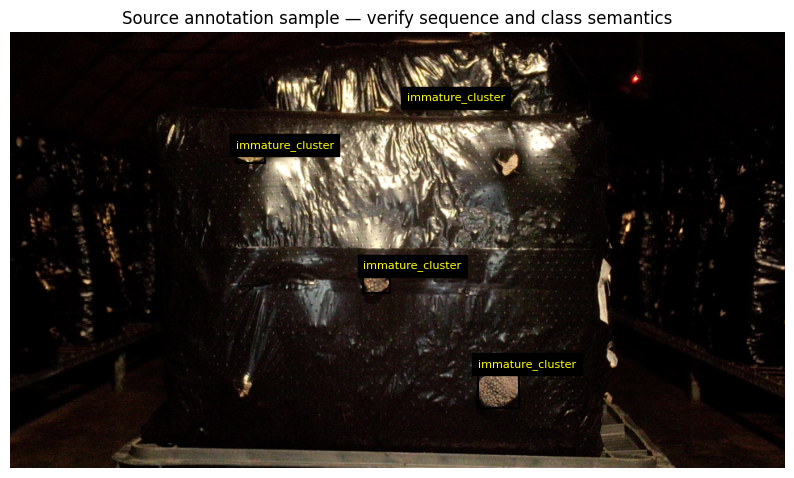

In [10]:
from pycocotools.coco import COCO

CAT_ID_TO_LABEL, LABEL_TO_NAME, NAME_TO_LABEL = make_contiguous_category_maps(COCO_DATA)
NUM_CLASSES = len(LABEL_TO_NAME) + 1  # background + dataset categories
print('Label mapping:', LABEL_TO_NAME)

train_ds = CocoInstanceDataset(COCO_JSON, DATA_ROOTS, train_image_ids, train=True)
val_ds = CocoInstanceDataset(COCO_JSON, DATA_ROOTS, val_image_ids, train=False)
test_ds = CocoInstanceDataset(COCO_JSON, DATA_ROOTS, test_image_ids, train=False)

# Validate one sample from each split and inspect annotation counts.
for split_name, ds in [('train', train_ds), ('validation', val_ds), ('test', test_ds)]:
    if len(ds) == 0:
        raise ValueError(f'{split_name} split is empty.')
    image, target = ds[0]
    print(split_name, 'tensor:', tuple(image.shape), 'instances:', int(target['labels'].numel()), 'labels:', target['labels'].tolist()[:10])

sample_img, sample_target = train_ds[0]
plt.figure(figsize=(10, 6))
plt.imshow(sample_img.permute(1,2,0))
for box, label in zip(sample_target['boxes'].numpy(), sample_target['labels'].numpy()):
    x1,y1,x2,y2 = box
    plt.gca().add_patch(plt.Rectangle((x1,y1),x2-x1,y2-y1,fill=False,linewidth=1.5))
    plt.text(x1, y1, LABEL_TO_NAME[int(label)], color='yellow', fontsize=8, backgroundcolor='black')
plt.title('Source annotation sample — verify sequence and class semantics')
plt.axis('off'); plt.show()

## Model

TorchVision Mask R-CNN with ConvNeXt-Tiny and FPN. ConvNeXt starts from ImageNet weights; the task-specific heads are trained on the Charisis classes.

In [11]:
class ConvNeXtTinyFPN(torch.nn.Module):
    def __init__(self, pretrained=True):
        super().__init__()
        weights = torchvision.models.ConvNeXt_Tiny_Weights.DEFAULT if pretrained else None
        model = torchvision.models.convnext_tiny(weights=weights)
        features = model.features
        # torchvision ConvNeXt-Tiny feature stages: stem, stage1, downsample, stage2, downsample, stage3, downsample, stage4
        self.stem = features[0]
        self.stage1 = features[1]
        self.down2 = features[2]
        self.stage2 = features[3]
        self.down3 = features[4]
        self.stage3 = features[5]
        self.down4 = features[6]
        self.stage4 = features[7]
        self.fpn = FeaturePyramidNetwork([96, 192, 384, 768], 256, extra_blocks=LastLevelMaxPool())
        self.out_channels = 256

    def forward(self, x):
        x = self.stem(x)
        c2 = self.stage1(x)
        c3 = self.stage2(self.down2(c2))
        c4 = self.stage3(self.down3(c3))
        c5 = self.stage4(self.down4(c4))
        return self.fpn(OrderedDict([('0', c2), ('1', c3), ('2', c4), ('3', c5)]))


def build_charisis_model(num_classes, min_size, max_size, pretrained_backbone=True):
    backbone = ConvNeXtTinyFPN(pretrained=pretrained_backbone)
    model = MaskRCNN(
        backbone,
        num_classes=num_classes,
        min_size=min_size,
        max_size=max_size,
        box_detections_per_img=BOX_DETECTIONS_PER_IMG,
        box_score_thresh=INFERENCE_SCORE_FLOOR,
        image_mean=[0.485, 0.456, 0.406],
        image_std=[0.229, 0.224, 0.225],
    )
    return model

if RUN_MODE == 'smoke':
    MIN_SIZE, MAX_SIZE = SMOKE_MIN_SIZE, SMOKE_MAX_SIZE
else:
    MIN_SIZE, MAX_SIZE = FULL_MIN_SIZE, FULL_MAX_SIZE

model = build_charisis_model(NUM_CLASSES, MIN_SIZE, MAX_SIZE, pretrained_backbone=True).to(DEVICE)
num_params = sum(p.numel() for p in model.parameters())
print('Model parameters:', f'{num_params:,}')
print('Input resize:', MIN_SIZE, MAX_SIZE)

Downloading: "https://download.pytorch.org/models/convnext_tiny-983f1562.pth" to /root/.cache/torch/hub/checkpoints/convnext_tiny-983f1562.pth


100%|██████████| 109M/109M [00:00<00:00, 222MB/s] 


Model parameters: 47,682,439
Input resize: 640 960


## Training

Train for 20 epochs. Save the last and best validation checkpoints after each epoch; resume from the last completed epoch.

In [12]:
train_loader = DataLoader(
    train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS,
    collate_fn=detection_collate, pin_memory=(DEVICE.type == 'cuda'),
    persistent_workers=(NUM_WORKERS > 0)
)
val_loader = DataLoader(
    val_ds, batch_size=1, shuffle=False, num_workers=NUM_WORKERS,
    collate_fn=detection_collate, pin_memory=(DEVICE.type == 'cuda'),
    persistent_workers=(NUM_WORKERS > 0)
)

optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=max(1, FULL_EPOCHS // 2), gamma=0.1)
scaler = torch.amp.GradScaler('cuda', enabled=USE_AMP)
LAST_CHECKPOINT = CHECKPOINT_ROOT / f'charisis_maskrcnn_convnext_tiny_{RUN_MODE}_last.pth'
BEST_CHECKPOINT = CHECKPOINT_ROOT / f'charisis_maskrcnn_convnext_tiny_{RUN_MODE}_best.pth'
BEST_METRICS_PATH = CHECKPOINT_ROOT / f'charisis_maskrcnn_convnext_tiny_{RUN_MODE}_best_validation.json'
START_EPOCH = 0
best_val_loss = float('inf')
if BEST_METRICS_PATH.exists():
    try:
        best_val_loss = float(json.loads(BEST_METRICS_PATH.read_text(encoding='utf-8')).get('validation_loss', float('inf')))
    except Exception:
        best_val_loss = float('inf')
history_path = RESULT_ROOT / f'training_history_{RUN_MODE}.csv'
history_rows = pd.read_csv(history_path).to_dict('records') if history_path.exists() else []

if RUN_MODE == 'full' and LAST_CHECKPOINT.exists():
    resume_payload = load_checkpoint(LAST_CHECKPOINT, model, optimizer, scaler, scheduler=scheduler, map_location=DEVICE)
    START_EPOCH = int(resume_payload.get('epoch_or_step', -1)) + 1
    print('Resuming after epoch:', START_EPOCH)

valid_history = [r for r in history_rows if np.isfinite(float(r.get('validation_loss', np.nan)))]
epochs_without_improvement = 0
if valid_history:
    best_history_epoch = int(min(valid_history, key=lambda r: float(r['validation_loss']))['epoch'])
    epochs_without_improvement = max(0, START_EPOCH - best_history_epoch)

num_epochs = 1 if RUN_MODE == 'smoke' else FULL_EPOCHS
training_start_time = time.time()
completed_epochs_this_session = 0
for epoch in range(START_EPOCH, num_epochs):
    epoch_start = time.time()
    train_loss, train_batches, successful_steps, skipped_steps = training_epoch(
        model, train_loader, optimizer, scaler, DEVICE,
        max_batches=(SMOKE_TRAIN_MAX_BATCHES if RUN_MODE == 'smoke' else None)
    )
    if successful_steps == 0:
        raise RuntimeError(f'No optimizer update succeeded in epoch {epoch + 1}; AMP/loss diagnostics: skipped={skipped_steps}.')
    val_loss = validation_loss(model, val_loader, DEVICE, max_batches=(2 if RUN_MODE == 'smoke' else None))
    scheduler.step()
    epoch_seconds = time.time() - epoch_start
    row = {
        'epoch': epoch + 1, 'train_loss': train_loss, 'validation_loss': val_loss,
        'train_batches': train_batches, 'successful_optimizer_steps': successful_steps,
        'skipped_optimizer_steps': skipped_steps, 'seconds': round(epoch_seconds, 1),
        'lr': optimizer.param_groups[0]['lr'], 'amp_scale': float(scaler.get_scale()),
    }
    print(row)
    history_rows.append(row)
    save_checkpoint(
        LAST_CHECKPOINT, model, optimizer, epoch,
        extra={'label_to_name': LABEL_TO_NAME, 'min_size': MIN_SIZE, 'max_size': MAX_SIZE,
               'architecture': 'TorchVision Mask R-CNN + ConvNeXt-Tiny-FPN',
               'successful_optimizer_steps': successful_steps, 'skipped_optimizer_steps': skipped_steps,
               'train_frame_stride': TRAIN_FRAME_STRIDE, 'test_frame_stride': TEST_FRAME_STRIDE},
        scaler=scaler, scheduler=scheduler,
    )
    improved = np.isfinite(val_loss) and val_loss < best_val_loss
    if improved:
        best_val_loss = float(val_loss)
        epochs_without_improvement = 0
        save_checkpoint(
            BEST_CHECKPOINT, model, optimizer, epoch,
            extra={'label_to_name': LABEL_TO_NAME, 'min_size': MIN_SIZE, 'max_size': MAX_SIZE,
                   'validation_loss': best_val_loss, 'architecture': 'TorchVision Mask R-CNN + ConvNeXt-Tiny-FPN'},
            scaler=scaler, scheduler=scheduler,
        )
        BEST_METRICS_PATH.write_text(json.dumps({'epoch': epoch + 1, 'validation_loss': best_val_loss}, indent=2), encoding='utf-8')
    else:
        epochs_without_improvement += 1

    completed_epochs_this_session += 1
    history_df = pd.DataFrame(history_rows).drop_duplicates(subset=['epoch'], keep='last').sort_values('epoch')
    history_df.to_csv(history_path, index=False)
    avg_epoch_seconds = float(history_df['seconds'].tail(3).mean())
    remaining_epochs = max(0, num_epochs - (epoch + 1))
    projected_remaining_hours = avg_epoch_seconds * remaining_epochs / 3600.0
    elapsed_hours = (time.time() - training_start_time) / 3600.0
    print(f'Runtime estimate: elapsed={elapsed_hours:.2f} h; projected remaining training={projected_remaining_hours:.2f} h; no-improvement validations={epochs_without_improvement}/{EARLY_STOPPING_PATIENCE}')

    if RUN_MODE == 'full' and (epoch + 1) >= 3 and epochs_without_improvement >= EARLY_STOPPING_PATIENCE:
        print('Early stopping: validation loss did not improve for', EARLY_STOPPING_PATIENCE, 'consecutive epochs.')
        break
    if RUN_MODE == 'full' and elapsed_hours >= MAX_TRAINING_HOURS:
        print(f'Training time budget reached ({MAX_TRAINING_HOURS:.1f} h). Keeping the best checkpoint for inference/export.')
        break

if history_rows:
    history_df = pd.DataFrame(history_rows).drop_duplicates(subset=['epoch'], keep='last').sort_values('epoch')
    history_df.to_csv(history_path, index=False)
    display(history_df)

selected_checkpoint = BEST_CHECKPOINT if BEST_CHECKPOINT.exists() else LAST_CHECKPOINT
if not selected_checkpoint.exists():
    raise FileNotFoundError('No checkpoint was saved. Review the training output above.')
reloaded_model = build_charisis_model(NUM_CLASSES, MIN_SIZE, MAX_SIZE, pretrained_backbone=False).to(DEVICE)
reloaded_payload = load_checkpoint(selected_checkpoint, reloaded_model, optimizer=None, scaler=None, map_location=DEVICE)
reloaded_model.eval()
print('Selected checkpoint:', selected_checkpoint.name,
      '| saved epoch:', reloaded_payload['epoch_or_step'] + 1,
      '| best validation loss:', best_val_loss,
      '| epochs completed this session:', completed_epochs_this_session)


train:   0%|          | 0/433 [00:00<?, ?it/s]

val-loss:   0%|          | 0/109 [00:00<?, ?it/s]

{'epoch': 1, 'train_loss': 1.0545772349861973, 'validation_loss': 0.6157406609539592, 'train_batches': 433, 'successful_optimizer_steps': 430, 'skipped_optimizer_steps': 3, 'seconds': 471.3, 'lr': 0.0001, 'amp_scale': 8192.0}


/tmp/ipykernel_50/3726889787.py:317: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  'created_utc': datetime.utcnow().isoformat() + 'Z',


Checkpoint saved: /kaggle/working/MushroomResearch/charisis_growth_tracking/checkpoints/charisis_maskrcnn_convnext_tiny_full_last.pth
Checkpoint saved: /kaggle/working/MushroomResearch/charisis_growth_tracking/checkpoints/charisis_maskrcnn_convnext_tiny_full_best.pth
Runtime estimate: elapsed=0.13 h; projected remaining training=1.18 h; no-improvement validations=0/3


train:   0%|          | 0/433 [00:00<?, ?it/s]

... (24 outputs left out)

val-loss:   0%|          | 0/109 [00:00<?, ?it/s]

{'epoch': 10, 'train_loss': 0.14485338285530963, 'validation_loss': 0.1648608377083726, 'train_batches': 433, 'successful_optimizer_steps': 433, 'skipped_optimizer_steps': 0, 'seconds': 435.7, 'lr': 1.0000000000000002e-06, 'amp_scale': 32768.0}
Checkpoint saved: /kaggle/working/MushroomResearch/charisis_growth_tracking/checkpoints/charisis_maskrcnn_convnext_tiny_full_last.pth
Checkpoint saved: /kaggle/working/MushroomResearch/charisis_growth_tracking/checkpoints/charisis_maskrcnn_convnext_tiny_full_best.pth
Runtime estimate: elapsed=1.22 h; projected remaining training=0.00 h; no-improvement validations=0/3


,epoch,train_loss,validation_loss,train_batches,successful_optimizer_steps,skipped_optimizer_steps,seconds,lr,amp_scale
0,1,1.054577,0.615741,433,430,3,471.3,0.000100,8192.0
1,2,0.468082,0.423366,433,433,0,429.7,0.000100,8192.0
2,3,0.352079,0.319589,433,433,0,440.5,0.000100,8192.0
3,4,0.310961,0.309995,433,433,0,434.3,0.000100,8192.0
4,5,0.272904,0.292967,433,433,0,435.0,0.000010,16384.0
5,6,0.181375,0.186885,433,433,0,428.1,0.000010,16384.0
6,7,0.160309,0.178059,433,433,0,427.2,0.000010,16384.0
7,8,0.151913,0.173942,433,433,0,433.5,0.000010,16384.0
8,9,0.146088,0.173585,433,433,0,437.8,0.000010,16384.0
9,10,0.144853,0.164861,433,433,0,435.7,0.000001,32768.0


Selected checkpoint: charisis_maskrcnn_convnext_tiny_full_best.pth | saved epoch: 10 | best validation loss: 0.1648608377083726 | epochs completed this session: 10


## Held-out inference

Run inference on every sampled frame in sequences 1 and 3. Process one image at a time and save masks at inference resolution. COCO AP uses candidates above the model score floor; tracking uses detections above the project threshold.

In [13]:
import gc
import os
import cv2
import json
import csv
import time
import resource
import numpy as np
import pandas as pd
import torch

from PIL import Image
from tqdm.auto import tqdm
from torchvision.transforms.functional import pil_to_tensor
from pycocotools import mask as mask_utils

if 'reloaded_model' not in globals() or reloaded_model is None:
    raise RuntimeError('Run the training/checkpoint cell before inference.')

# COCO AP needs low-score candidates; the operational threshold is applied only when creating tracking rows.
reloaded_model.roi_heads.score_thresh = float(INFERENCE_SCORE_FLOOR)
reloaded_model.roi_heads.detections_per_img = int(BOX_DETECTIONS_PER_IMG)

required_variables = [
    'COCO_DATA', 'CAT_ID_TO_LABEL', 'LABEL_TO_NAME', 'inference_image_ids',
    'image_sequence', 'DATA_ROOTS', 'IMAGE_INDEX', 'RESULT_ROOT', 'DEVICE',
    'RUN_MODE', 'MASK_THRESHOLD', 'CONFIDENCE_THRESHOLD', 'COCO_JSON'
]
missing = [name for name in required_variables if name not in globals()]
if missing:
    raise RuntimeError(f'Missing required variables: {missing}')

RESULT_ROOT.mkdir(parents=True, exist_ok=True)
STREAM_DIR = RESULT_ROOT / 'streaming_inference'
MASK_DIR = STREAM_DIR / 'masks'
MASK_DIR.mkdir(parents=True, exist_ok=True)

CSV_PATH = STREAM_DIR / 'test_detections.csv'
COCO_JSONL_PATH = STREAM_DIR / 'coco_predictions.jsonl'
TRACK_JSONL_PATH = STREAM_DIR / 'tracking_metadata.jsonl'
DIAGNOSTICS_PATH = STREAM_DIR / 'inference_diagnostics.csv'

# This is the order used by the tracking cell. Metadata remains grouped by image.
def _frame_sort_key(image_id):
    rec = COCO_IMAGE_LOOKUP[int(image_id)]
    nums = re.findall(r'\d+', Path(str(rec['file_name'])).stem)
    return (int(image_sequence[int(image_id)]), int(nums[-1]) if nums else int(image_id), int(image_id))

COCO_IMAGE_LOOKUP = {int(x['id']): x for x in COCO_DATA['images']}
inference_image_ids = sorted([int(x) for x in inference_image_ids], key=_frame_sort_key)

# Smoke output is disposable. Full inference resumes from completed image IDs.
if RUN_MODE == 'smoke':
    for path in [CSV_PATH, COCO_JSONL_PATH, TRACK_JSONL_PATH, DIAGNOSTICS_PATH]:
        if path.exists():
            path.unlink()
    for file_path in MASK_DIR.glob('*.png'):
        file_path.unlink()

completed_inference_ids = set()
if RUN_MODE == 'full' and DIAGNOSTICS_PATH.exists():
    try:
        previous_diagnostics = pd.read_csv(DIAGNOSTICS_PATH)
        completed_inference_ids = set(previous_diagnostics['image_id'].dropna().astype(int).tolist())
    except Exception as e:
        raise RuntimeError(f'Existing inference diagnostics could not be read; do not overwrite partial results blindly: {e}')
    print('Resuming inference; completed images:', len(completed_inference_ids), '/', len(inference_image_ids))

    # A runtime may stop halfway through one image. Keep records only for images
    # whose diagnostics row was written (the per-image commit marker).
    if CSV_PATH.exists():
        try:
            previous_rows = pd.read_csv(CSV_PATH)
            if 'image_id' in previous_rows:
                previous_rows = previous_rows[previous_rows['image_id'].astype(int).isin(completed_inference_ids)]
                previous_rows.to_csv(CSV_PATH, index=False)
        except Exception as e:
            raise RuntimeError(f'Could not clean partial detection CSV before resume: {e}')
    for jsonl_path in [COCO_JSONL_PATH, TRACK_JSONL_PATH]:
        if jsonl_path.exists():
            temp_path = jsonl_path.with_suffix(jsonl_path.suffix + '.clean')
            with open(jsonl_path, 'r', encoding='utf-8') as source, open(temp_path, 'w', encoding='utf-8') as target:
                for line in source:
                    try:
                        record = json.loads(line)
                        if int(record.get('image_id', -1)) in completed_inference_ids:
                            target.write(json.dumps(record) + '\n')
                    except Exception:
                        continue  # discard an incomplete final line
            os.replace(temp_path, jsonl_path)

# Avoid TorchVision silently upscaling the already-resized image to the
# model's training min_size. This keeps inference bounded on a Colab T4.
INFERENCE_SIDE = int(MAX_INFERENCE_SIDE)
reloaded_model.transform.min_size = (INFERENCE_SIDE,)
reloaded_model.transform.max_size = INFERENCE_SIDE
reloaded_model.roi_heads.score_thresh = float(INFERENCE_SCORE_FLOOR)
reloaded_model.roi_heads.detections_per_img = int(BOX_DETECTIONS_PER_IMG)
reloaded_model.eval()

cat_label_to_original_id = {label: cat_id for cat_id, label in CAT_ID_TO_LABEL.items()}

def _process_one_image(image_id):
    rec = COCO_IMAGE_LOOKUP[int(image_id)]
    image_path = resolve_image(rec['file_name'], DATA_ROOTS, IMAGE_INDEX)
    with Image.open(image_path) as im:
        image = im.convert('RGB')
    original_w, original_h = image.size
    scale = min(1.0, INFERENCE_SIDE / max(original_w, original_h))
    resized_w = max(1, round(original_w * scale))
    resized_h = max(1, round(original_h * scale))
    if (resized_w, resized_h) != (original_w, original_h):
        small_image = image.resize((resized_w, resized_h), Image.Resampling.BILINEAR)
    else:
        small_image = image

    tensor = pil_to_tensor(small_image).to(device=DEVICE, dtype=torch.float32) / 255.0
    if torch.cuda.is_available():
        torch.cuda.reset_peak_memory_stats()
    start_time = time.time()
    with torch.inference_mode():
        prediction = reloaded_model([tensor])[0]

    boxes = prediction['boxes'].detach().cpu().numpy()
    labels = prediction['labels'].detach().cpu().numpy()
    scores = prediction['scores'].detach().cpu().numpy()
    masks_gpu = prediction['masks']
    raw_candidate_count = int(len(scores))
    cap_reached = raw_candidate_count >= int(BOX_DETECTIONS_PER_IMG)

    rows = []
    candidate_scores = []
    accepted = 0
    image_mask_dir = MASK_DIR
    with open(COCO_JSONL_PATH, 'a', encoding='utf-8') as coco_file, open(TRACK_JSONL_PATH, 'a', encoding='utf-8') as track_file:
        for det_idx in range(raw_candidate_count):
            score = float(scores[det_idx])
            label = int(labels[det_idx])
            if label not in cat_label_to_original_id:
                continue
            candidate_scores.append(score)
            # Save a low-resolution mask. The full-resolution mask is created
            # one at a time only for area/RLE calculation, then released.
            mask_model = (masks_gpu[det_idx, 0] >= MASK_THRESHOLD).to(torch.uint8).cpu().numpy()
            if int(mask_model.sum()) == 0:
                del mask_model
                continue
            mask_name = f"seq{int(image_sequence[int(image_id)]):02d}_image_{int(image_id)}_det_{det_idx}.png"
            mask_path = image_mask_dir / mask_name
            if not cv2.imwrite(str(mask_path), mask_model * 255):
                raise IOError(f'Could not write mask: {mask_path}')

            box = boxes[det_idx].copy()
            box[[0, 2]] /= (resized_w / original_w)
            box[[1, 3]] /= (resized_h / original_h)
            x1, y1, x2, y2 = [float(x) for x in box]
            x1, x2 = float(np.clip(x1, 0, original_w)), float(np.clip(x2, 0, original_w))
            y1, y2 = float(np.clip(y1, 0, original_h)), float(np.clip(y2, 0, original_h))
            category_id = int(cat_label_to_original_id[label])

            # Area and COCO RLE are in source-image pixels, but only one
            # expanded mask exists at a time.
            full_mask = cv2.resize(mask_model, (original_w, original_h), interpolation=cv2.INTER_NEAREST)
            area_px2 = int(full_mask.sum())
            if area_px2 == 0:
                mask_path.unlink(missing_ok=True)
                del mask_model, full_mask
                continue

            row = {
                'image_id': int(image_id),
                'file_name': rec['file_name'],
                'sequence_id': int(image_sequence[int(image_id)]),
                'detection_index': int(det_idx),
                'class_name': LABEL_TO_NAME[label],
                'category_id': category_id,
                'confidence': score,
                'bbox_x1': x1, 'bbox_y1': y1, 'bbox_x2': x2, 'bbox_y2': y2,
                'area_px2': area_px2,
                'mask_path': str(mask_path),
                'mask_width': int(resized_w), 'mask_height': int(resized_h),
            }
            # COCO AP needs the full ranked candidate list above the model
            # score floor. Do not truncate it at the final tracking threshold.
            rle = mask_utils.encode(np.asfortranarray(full_mask.astype(np.uint8)))
            rle['counts'] = rle['counts'].decode('ascii')
            coco_item = {
                'image_id': int(image_id), 'category_id': category_id,
                'bbox': [x1, y1, max(0.0, x2-x1), max(0.0, y2-y1)],
                'score': score, 'segmentation': rle,
            }
            coco_file.write(json.dumps(coco_item) + '\n')
            del rle, coco_item

            # Persistent tracks use only detections passing the project threshold.
            if score >= CONFIDENCE_THRESHOLD:
                rows.append(row)
                accepted += 1
                track_item = {
                    **row,
                    'label': label,
                    'bbox': [x1, y1, x2, y2],
                    'image_shape': [original_h, original_w],
                }
                track_file.write(json.dumps(track_item) + '\n')
                del track_item
            else:
                # Keep the low-confidence mask only as a diagnostic candidate.
                diag_dir = STREAM_DIR / 'low_confidence_candidates'
                diag_dir.mkdir(parents=True, exist_ok=True)
                cv2.imwrite(str(diag_dir / mask_name), mask_model * 255)
                mask_path.unlink(missing_ok=True)
            del mask_model, full_mask

    diagnostics = {
        'image_id': int(image_id),
        'sequence_id': int(image_sequence[int(image_id)]),
        'file_name': rec['file_name'],
        'model_candidates_returned': raw_candidate_count,
        'detection_cap': int(BOX_DETECTIONS_PER_IMG),
        'detection_cap_reached': cap_reached,
        'accepted_detections': accepted,
        'score_min': min(candidate_scores) if candidate_scores else None,
        'score_mean': float(np.mean(candidate_scores)) if candidate_scores else None,
        'score_max': max(candidate_scores) if candidate_scores else None,
        'score_ge_project_threshold': int(sum(s >= CONFIDENCE_THRESHOLD for s in candidate_scores)),
        'inference_seconds': round(time.time() - start_time, 3),
        'gpu_peak_allocated_mb': round(torch.cuda.max_memory_allocated() / 1024**2, 1) if torch.cuda.is_available() else None,
        'process_max_rss_mb': round(resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / (1024 if sys.platform != 'darwin' else 1024**2), 1),
    }

    del tensor, small_image, image, prediction, masks_gpu, boxes, labels, scores
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    return rows, diagnostics

all_rows_count = 0
for image_id in tqdm(inference_image_ids, desc='Streaming inference'):
    if int(image_id) in completed_inference_ids:
        continue
    rows, diag = _process_one_image(image_id)
    if rows:
        pd.DataFrame(rows).to_csv(CSV_PATH, mode='a', header=not CSV_PATH.exists(), index=False)
        all_rows_count += len(rows)
    # Write diagnostics last: this row is the commit marker for a complete image.
    pd.DataFrame([diag]).to_csv(DIAGNOSTICS_PATH, mode='a', header=not DIAGNOSTICS_PATH.exists(), index=False)
    del rows, diag
    gc.collect()

print('\n========== INFERENCE SUMMARY ==========')
print('Evaluated images:', len(inference_image_ids))
print('Completed images in diagnostics:', len(pd.read_csv(DIAGNOSTICS_PATH)) if DIAGNOSTICS_PATH.exists() else 0)
print('Accepted detections:', all_rows_count)
print('Detection CSV:', CSV_PATH)
print('COCO predictions:', COCO_JSONL_PATH)
print('Tracking metadata:', TRACK_JSONL_PATH)
print('Inference diagnostics:', DIAGNOSTICS_PATH)
print('Low-confidence mask previews:', STREAM_DIR / 'low_confidence_candidates')
if DIAGNOSTICS_PATH.exists():
    diag_df = pd.read_csv(DIAGNOSTICS_PATH)
    print('Images at detection cap:', int(diag_df['detection_cap_reached'].sum()), '/', len(diag_df))
    print('Peak process RSS (MB):', float(diag_df['process_max_rss_mb'].max()))
    if torch.cuda.is_available():
        print('Peak GPU allocation (MB):', float(diag_df['gpu_peak_allocated_mb'].max()))
print('Inference completed.')

Streaming inference:   0%|          | 0/1055 [00:00<?, ?it/s]


========== INFERENCE SUMMARY ==========
Evaluated images: 1055
Completed images in diagnostics: 1055
Accepted detections: 9483
Detection CSV: /kaggle/working/MushroomResearch/charisis_growth_tracking/results/full/streaming_inference/test_detections.csv
COCO predictions: /kaggle/working/MushroomResearch/charisis_growth_tracking/results/full/streaming_inference/coco_predictions.jsonl
Tracking metadata: /kaggle/working/MushroomResearch/charisis_growth_tracking/results/full/streaming_inference/tracking_metadata.jsonl
Inference diagnostics: /kaggle/working/MushroomResearch/charisis_growth_tracking/results/full/streaming_inference/inference_diagnostics.csv
Low-confidence mask previews: /kaggle/working/MushroomResearch/charisis_growth_tracking/results/full/streaming_inference/low_confidence_candidates
Images at detection cap: 0 / 1055
Peak process RSS (MB): 4709.7
Peak GPU allocation (MB): 1792.7
Inference completed.


In [14]:
from pathlib import Path
import gc
import io
import json
from contextlib import redirect_stdout
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval

STREAM_DIR = Path(RESULT_ROOT) / 'streaming_inference'
COCO_JSONL_PATH = STREAM_DIR / 'coco_predictions.jsonl'
COCO_JSON = Path(COCO_JSON)
COCO_ARRAY_PATH = STREAM_DIR / 'coco_predictions_array.json'
METRICS_JSON_PATH = RESULT_ROOT / 'coco_metrics_stats.json'
METRICS_TXT_PATH = RESULT_ROOT / 'coco_metrics_summary.txt'

# Convert JSONL to a COCO result array without loading every prediction into RAM.
print('Preparing COCO mask evaluation...')
with open(COCO_JSONL_PATH, 'r', encoding='utf-8') as fin, open(COCO_ARRAY_PATH, 'w', encoding='utf-8') as fout:
    fout.write('[\n')
    first = True
    for line in fin:
        if not line.strip():
            continue
        if not first:
            fout.write(',\n')
        fout.write(line.strip())
        first = False
    fout.write('\n]')

gc.collect()
coco_gt = COCO(str(COCO_JSON))
if not inference_image_ids:
    raise RuntimeError('The held-out test split is empty; check the sequence split cell.')

if COCO_ARRAY_PATH.stat().st_size <= 5:
    # Keep Run all moving and make the failure visible in the metrics artifact.
    category_names = [str(c['name']) for c in COCO_DATA['categories']]
    metrics = {
        'AP': 0.0, 'AP50': 0.0, 'AP75': 0.0,
        'AR1': 0.0, 'AR10': 0.0, 'AR100': 0.0,
        'images_evaluated': len(inference_image_ids),
        'accepted_detections': 0,
        'per_class': {name: {'AP': 0.0, 'AP50': 0.0, 'AP75': 0.0} for name in category_names},
        'note': 'No model candidates were written; inspect inference_diagnostics.csv.',
    }
    METRICS_TXT_PATH.write_text(metrics['note'], encoding='utf-8')
    METRICS_JSON_PATH.write_text(json.dumps(metrics, indent=2), encoding='utf-8')
    print(metrics['note'])
else:
    coco_dt = coco_gt.loadRes(str(COCO_ARRAY_PATH))
    coco_eval = COCOeval(coco_gt, coco_dt, 'segm')
    coco_eval.params.imgIds = [int(x) for x in inference_image_ids]
    coco_eval.evaluate()
    coco_eval.accumulate()
    output = io.StringIO()
    with redirect_stdout(output):
        coco_eval.summarize()
    summary_text = output.getvalue()
    print(summary_text)
    METRICS_TXT_PATH.write_text(summary_text, encoding='utf-8')

    stats = coco_eval.stats
    metrics = {
        'AP': float(stats[0]), 'AP50': float(stats[1]), 'AP75': float(stats[2]),
        'AP_small': float(stats[3]), 'AP_medium': float(stats[4]), 'AP_large': float(stats[5]),
        'AR1': float(stats[6]), 'AR10': float(stats[7]), 'AR100': float(stats[8]),
        'AR_small': float(stats[9]), 'AR_medium': float(stats[10]), 'AR_large': float(stats[11]),
        'images_evaluated': len(inference_image_ids),
        'candidate_predictions': int(len(coco_dt.getAnnIds())),
    }

    per_class = {}
    for category in coco_gt.loadCats(coco_gt.getCatIds()):
        class_eval = COCOeval(coco_gt, coco_dt, 'segm')
        class_eval.params.imgIds = [int(x) for x in inference_image_ids]
        class_eval.params.catIds = [int(category['id'])]
        class_eval.evaluate()
        class_eval.accumulate()
        class_eval.summarize()
        per_class[str(category['name'])] = {
            'AP': float(class_eval.stats[0]),
            'AP50': float(class_eval.stats[1]),
            'AP75': float(class_eval.stats[2]),
        }
    metrics['per_class'] = per_class
    METRICS_JSON_PATH.write_text(json.dumps(metrics, indent=2), encoding='utf-8')
    del coco_dt, coco_eval, class_eval

if COCO_ARRAY_PATH.exists():
    COCO_ARRAY_PATH.unlink()
del coco_gt
gc.collect()
print('Saved metrics:', METRICS_JSON_PATH)


Preparing COCO mask evaluation...
loading annotations into memory...
Done (t=1.06s)
creating index...
index created!
Loading and preparing results...
DONE (t=0.15s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *segm*
DONE (t=3.12s).
Accumulating evaluation results...
DONE (t=0.26s).
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.650
 Average Precision  (AP) @[ IoU=0.50      | area=   all | maxDets=100 ] = 0.782
 Average Precision  (AP) @[ IoU=0.75      | area=   all | maxDets=100 ] = 0.759
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= small | maxDets=100 ] = -1.000
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=medium | maxDets=100 ] = 0.333
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= large | maxDets=100 ] = 0.654
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=  1 ] = 0.217
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets= 10 ] = 0.759
 Average Recall     (AR) @[ Io

## Tracking

Associate detections within each sequence using downsampled mask IoU, center distance and area similarity. Load one frame's masks at a time and export track observations and summaries.

In [15]:
# --- Bổ sung khai báo lại đường dẫn và biến (bỏ qua inference) ---
STREAM_DIR = RESULT_ROOT / 'streaming_inference'
TRACK_JSONL_PATH = STREAM_DIR / 'tracking_metadata.jsonl'
COCO_IMAGE_LOOKUP = {int(x['id']): x for x in COCO_DATA['images']}
# -----------------------------------------------------------------

import gc
import re
import json
from datetime import datetime, timezone
from pathlib import Path
from collections import defaultdict
import numpy as np
import pandas as pd
from PIL import Image
from scipy.optimize import linear_sum_assignment
from itertools import groupby

TIMESTAMP_PATTERNS = [
    re.compile(r'(20\d{2}[-_]\d{2}[-_]\d{2})[T _-](\d{2}[-_:]\d{2}[-_:]\d{2})'),
    re.compile(r'(20\d{2})(\d{2})(\d{2})[_-]?(\d{2})(\d{2})(\d{2})'),
]

def parse_image_timestamp(file_name, image_id=None):
    if image_id is not None and int(image_id) in COCO_IMAGE_LOOKUP:
        rec = COCO_IMAGE_LOOKUP[int(image_id)]
        for key in ['timestamp', 'date_captured', 'datetime', 'captured_at']:
            value = rec.get(key)
            if value not in (None, '', 0, 0.0, '0', '1970-01-01T00:00:00'):
                try:
                    if isinstance(value, (int, float)):
                        return datetime.fromtimestamp(float(value), tz=timezone.utc).isoformat()
                    return datetime.fromisoformat(str(value).replace('Z', '+00:00')).isoformat()
                except Exception:
                    pass
    name = Path(str(file_name)).stem
    match = TIMESTAMP_PATTERNS[0].search(name)
    if match:
        try:
            return datetime.fromisoformat(match.group(1).replace('_', '-') + 'T' + re.sub(r'[-_:]', ':', match.group(2))).isoformat()
        except Exception:
            pass
    match = TIMESTAMP_PATTERNS[1].search(name)
    if match:
        try:
            return datetime(*(int(x) for x in match.groups())).isoformat()
        except Exception:
            pass
    return None

def normalized_center(bbox):
    x1, y1, x2, y2 = bbox
    return np.array([(x1+x2)/2, (y1+y2)/2], dtype=float)

def load_tracking_mask(mask_path, max_side=TRACK_MASK_MAX_SIDE):
    with Image.open(mask_path) as im:
        mask = im.convert('L')
        mask.thumbnail((max_side, max_side), Image.Resampling.NEAREST)
        return np.asarray(mask) > 0

def mask_iou(a, b):
    a = np.asarray(a, dtype=bool)
    b = np.asarray(b, dtype=bool)
    if a.shape != b.shape:
        h, w = min(a.shape[0], b.shape[0]), min(a.shape[1], b.shape[1])
        a = np.asarray(Image.fromarray(a.astype('uint8')).resize((w, h), Image.Resampling.NEAREST)) > 0
        b = np.asarray(Image.fromarray(b.astype('uint8')).resize((w, h), Image.Resampling.NEAREST)) > 0
    inter = np.logical_and(a, b).sum()
    union = np.logical_or(a, b).sum()
    return float(inter / union) if union else 0.0

def pair_similarity(track, det, image_diag):
    iou = mask_iou(track['small_mask'], det['small_mask'])
    c1, c2 = normalized_center(track['bbox']), normalized_center(det['bbox'])
    dist = float(np.linalg.norm(c1-c2))
    area_ratio = min(track['area_px2'], det['area_px2']) / max(track['area_px2'], det['area_px2'], 1.0)
    center_affinity = float(np.exp(-dist / max(1.0, 0.08 * image_diag)))
    score = 0.65 * iou + 0.20 * center_affinity + 0.15 * area_ratio
    valid = (dist <= 0.18 * image_diag) and (area_ratio >= 0.08) and (score >= TRACK_ACCEPTANCE_SCORE)
    return score if valid else -1.0


if not TRACK_JSONL_PATH.exists():
    raise FileNotFoundError(f'Inference metadata missing: {TRACK_JSONL_PATH}. Run inference first.')

# --- CƠ CHẾ TRA CỨU MỚI: Loại bỏ hoàn toàn lỗi "Out-of-order" ---
print("Đang nạp file tracking metadata vào bộ nhớ để tra cứu...")
all_detections_by_image = defaultdict(list)
with open(TRACK_JSONL_PATH, 'r', encoding='utf-8') as f:
    for line in f:
        if line.strip():
            item = json.loads(line)
            all_detections_by_image[int(item['image_id'])].append(item)

def take_frame_detections(image_id):
    # Trả về danh sách predictions của ảnh đó, bất kể thứ tự file là gì
    return all_detections_by_image.get(int(image_id), [])
# ----------------------------------------------------------------


tracks_path = RESULT_ROOT / 'cluster_tracks.csv'
summary_path = RESULT_ROOT / 'cluster_track_summary.csv'
track_columns = [
    'image_id','file_name','sequence_id','frame_index','timestamp','track_id',
    'class_name','confidence','bbox_x1','bbox_y1','bbox_x2','bbox_y2',
    'area_px2','first_area_px2','growth_vs_first_pct','association_score',
    'detection_index','mask_path'
]
summary_columns = [
    'sequence_id','track_id','first_frame_index','last_frame_index','observations',
    'first_area_px2','last_area_px2','growth_vs_first_pct','end_reason'
]
if tracks_path.exists(): tracks_path.unlink()
if summary_path.exists(): summary_path.unlink()

track_buffer = []
summary_rows = []
next_global_track_counts = defaultdict(int)

def flush_track_buffer():
    if not track_buffer:
        return
    pd.DataFrame(track_buffer, columns=track_columns).to_csv(
        tracks_path, mode='a', header=not tracks_path.exists(), index=False
    )
    track_buffer.clear()

def close_track(sequence_id, track_id, state, end_reason):
    summary_rows.append({
        'sequence_id': int(sequence_id),
        'track_id': str(track_id),
        'first_frame_index': int(state['first_frame']),
        'last_frame_index': int(state['last_frame']),
        'observations': int(state['observations']),
        'first_area_px2': float(state['first_area']),
        'last_area_px2': float(state['area_px2']),
        'growth_vs_first_pct': 100.0 * (float(state['area_px2']) / max(float(state['first_area']), 1.0) - 1.0),
        'end_reason': end_reason,
    })

for seq_id in sorted(TEST_SEQUENCE_IDS):
    seq_image_ids = [i for i in inference_image_ids if image_sequence[int(i)] == int(seq_id)]
    active = {}
    next_id = 1
    for frame_index, image_id in enumerate(seq_image_ids):
        rec = COCO_IMAGE_LOOKUP[int(image_id)]
        raw_detections = take_frame_detections(image_id)
        detections = []
        for item in raw_detections:
            mask_path = Path(item.get('mask_path', ''))
            if not mask_path.exists():
                raise FileNotFoundError(f'Tracking mask is missing: {mask_path}')
            detection = dict(item)
            detection['small_mask'] = load_tracking_mask(mask_path)

            # --- XỬ LÝ LỖI KEY BẰNG CÁCH DÙNG FALLBACK ---
            detection['bbox'] = [float(x) for x in item.get('bbox', [0, 0, 0, 0])]
            detection['area_px2'] = float(item.get('area_px2', item.get('area', 0.0)))
            detection['score'] = float(item.get('confidence', item.get('score', 0.0)))
            detection['label'] = int(item.get('label', item.get('category_id', 0)))
            detection['detection_index'] = int(item.get('detection_index', 0))
            # ---------------------------------------------

            detections.append(detection)

        image_diag = float(np.hypot(int(rec.get('height', 0)), int(rec.get('width', 0))))
        track_ids = list(active.keys())
        matches = []
        if track_ids and detections:
            similarity = np.full((len(track_ids), len(detections)), -1.0, dtype=np.float32)
            for ti, tid in enumerate(track_ids):
                for di, det in enumerate(detections):
                    similarity[ti, di] = pair_similarity(active[tid], det, image_diag)
            cost = np.where(similarity >= 0, 1.0 - similarity, 1e6)
            row_idx, col_idx = linear_sum_assignment(cost)
            for ri, ci in zip(row_idx, col_idx):
                if similarity[ri, ci] >= TRACK_ACCEPTANCE_SCORE:
                    matches.append((track_ids[ri], int(ci), float(similarity[ri, ci])))

        matched_tracks, matched_detections = set(), set()
        for tid, det_idx, similarity_score in matches:
            det = detections[det_idx]
            previous = active[tid]
            active[tid] = {
                **det,
                'missed': 0,
                'last_frame': frame_index,
                'first_frame': previous['first_frame'],
                'first_area': previous['first_area'],
                'observations': previous['observations'] + 1,
            }
            matched_tracks.add(tid)
            matched_detections.add(det_idx)
            track_buffer.append({
                'image_id': int(image_id), 'file_name': rec['file_name'],
                'sequence_id': int(seq_id), 'frame_index': frame_index,
                'timestamp': parse_image_timestamp(rec['file_name'], image_id),
                'track_id': tid, 'class_name': LABEL_TO_NAME.get(int(det['label']), str(det['label'])),
                'confidence': float(det['score']),
                'bbox_x1': det['bbox'][0], 'bbox_y1': det['bbox'][1],
                'bbox_x2': det['bbox'][2], 'bbox_y2': det['bbox'][3],
                'area_px2': float(det['area_px2']),
                'first_area_px2': float(previous['first_area']),
                'growth_vs_first_pct': 100.0 * (float(det['area_px2']) / max(float(previous['first_area']), 1.0) - 1.0),
                'association_score': similarity_score,
                'detection_index': int(det['detection_index']),
                'mask_path': str(det.get('mask_path', '')),
            })

        for tid in list(active.keys()):
            if tid not in matched_tracks:
                active[tid]['missed'] += 1
                if active[tid]['missed'] > MAX_MISSED_FRAMES:
                    close_track(seq_id, tid, active[tid], 'not_observed_again_after_gap')
                    del active[tid]

        for det_idx, det in enumerate(detections):
            if det_idx in matched_detections:
                continue
            tid = f'S{int(seq_id):02d}_C{next_id:05d}'
            next_id += 1
            active[tid] = {
                **det, 'missed': 0, 'last_frame': frame_index,
                'first_frame': frame_index, 'first_area': float(det['area_px2']),
                'observations': 1,
            }
            track_buffer.append({
                'image_id': int(image_id), 'file_name': rec['file_name'],
                'sequence_id': int(seq_id), 'frame_index': frame_index,
                'timestamp': parse_image_timestamp(rec['file_name'], image_id),
                'track_id': tid, 'class_name': LABEL_TO_NAME.get(int(det['label']), str(det['label'])),
                'confidence': float(det['score']),
                'bbox_x1': det['bbox'][0], 'bbox_y1': det['bbox'][1],
                'bbox_x2': det['bbox'][2], 'bbox_y2': det['bbox'][3],
                'area_px2': float(det['area_px2']),
                'first_area_px2': float(det['area_px2']),
                'growth_vs_first_pct': 0.0,
                'association_score': None,
                'detection_index': int(det['detection_index']),
                'mask_path': str(det.get('mask_path', '')),
            })

        del detections, raw_detections
        if len(track_buffer) >= 5000:
            flush_track_buffer()
        if frame_index % 50 == 0:
            gc.collect()

    for tid, state in active.items():
        close_track(seq_id, tid, state, 'last_frame_observed')
    active.clear()
    gc.collect()

flush_track_buffer()
pd.DataFrame(summary_rows, columns=summary_columns).to_csv(summary_path, index=False)
tracks_df = pd.read_csv(tracks_path) if tracks_path.exists() else pd.DataFrame(columns=track_columns)
summary_df = pd.DataFrame(summary_rows, columns=summary_columns)
print('Tracked observations:', len(tracks_df), '| tracks:', len(summary_df))
print('Track rows:', tracks_path)
print('Track summary:', summary_path)
display(summary_df.head(20))

Đang nạp file tracking metadata vào bộ nhớ để tra cứu...
Tracked observations: 9483 | tracks: 213
Track rows: /kaggle/working/MushroomResearch/charisis_growth_tracking/results/full/cluster_tracks.csv
Track summary: /kaggle/working/MushroomResearch/charisis_growth_tracking/results/full/cluster_track_summary.csv


,sequence_id,track_id,first_frame_index,last_frame_index,observations,first_area_px2,last_area_px2,growth_vs_first_pct,end_reason
0,1,S01_C00004,2,2,1,16393.0,16393.0,0.000000,not_observed_again_after_gap
1,1,S01_C00003,0,6,7,16323.0,15657.0,-4.080132,not_observed_again_after_gap
2,1,S01_C00012,18,18,1,67734.0,67734.0,0.000000,not_observed_again_after_gap
3,1,S01_C00011,18,19,2,11690.0,13052.0,11.650984,not_observed_again_after_gap
4,1,S01_C00005,3,43,39,7453.0,287671.0,3759.801422,not_observed_again_after_gap
5,1,S01_C00017,41,45,5,225503.0,245504.0,8.869505,not_observed_again_after_gap
6,1,S01_C00019,48,53,6,195238.0,244140.0,25.047378,not_observed_again_after_gap
7,1,S01_C00020,53,55,3,486891.0,536605.0,10.210499,not_observed_again_after_gap
8,1,S01_C00018,43,58,12,239307.0,386505.0,61.510110,not_observed_again_after_gap
9,1,S01_C00008,13,59,47,13586.0,176116.0,1196.305020,not_observed_again_after_gap


## Growth output

Export pixel-area growth curves. These are pixel measurements, not calibrated physical dimensions.

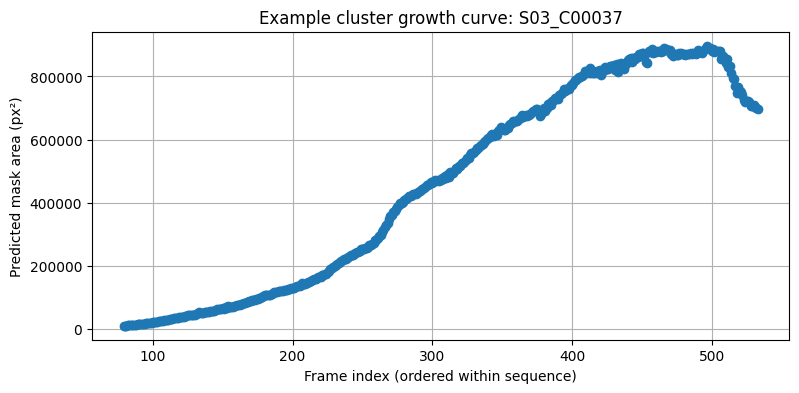

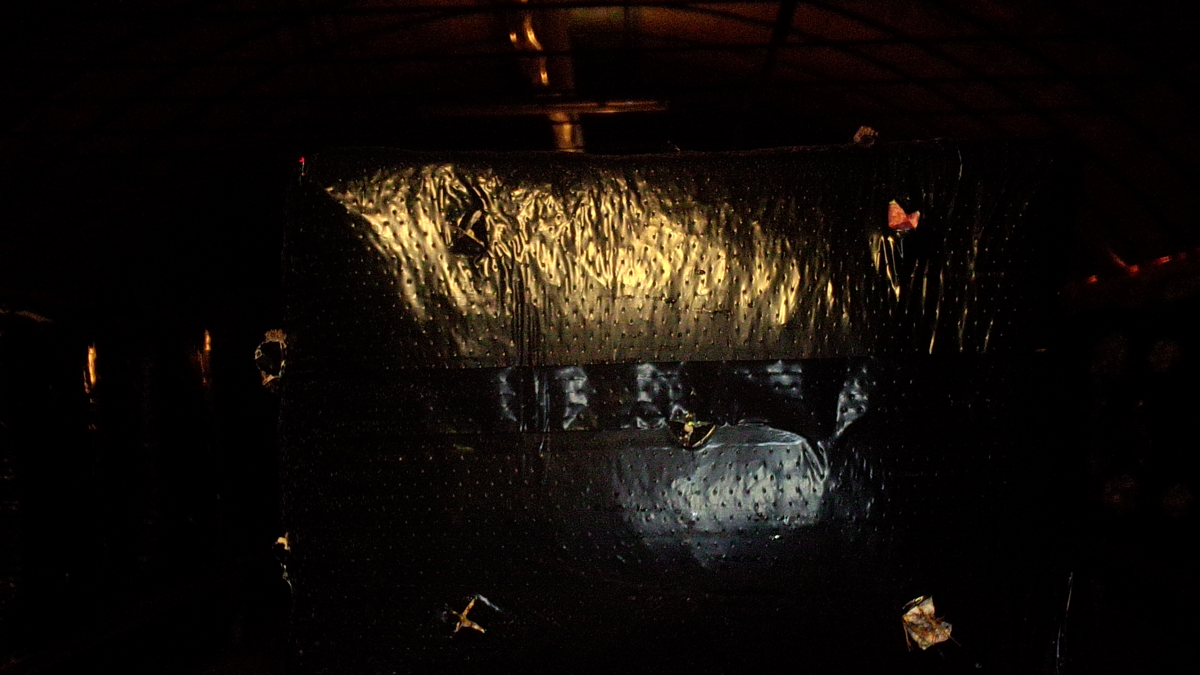

Model bundle: /kaggle/working/MushroomResearch/charisis_growth_tracking/model_bundle.zip
Notebook outputs are stored under: /kaggle/working/MushroomResearch/charisis_growth_tracking


In [16]:
import json
from datetime import timezone, datetime
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt

# --- 1. Vẽ biểu đồ tăng trưởng ---
if len(tracks_df) and len(summary_df):
    longest = summary_df.sort_values('observations', ascending=False).iloc[0]
    tid = longest['track_id']
    curve = tracks_df[tracks_df['track_id'].astype(str) == str(tid)].sort_values('frame_index')
    plt.figure(figsize=(9, 4))
    plt.plot(curve['frame_index'], curve['area_px2'], marker='o')
    plt.xlabel('Frame index (ordered within sequence)')
    plt.ylabel('Predicted mask area (px²)')
    plt.title(f'Example cluster growth curve: {tid}')
    plt.grid(True)
    plt.show()
else:
    print('No accepted detections were available for tracking in the selected test frames.')

# --- 2. Xem trước mask được track ---
try:
    if len(tracks_df):
        first = tracks_df.iloc[0]
        img_rec = COCO_IMAGE_LOOKUP[int(first['image_id'])]
        image_path = resolve_image(img_rec['file_name'], DATA_ROOTS, IMAGE_INDEX)
        with Image.open(image_path) as im:
            preview = im.convert('RGB')
        mask_path = Path(first['mask_path'])
        with Image.open(mask_path) as im:
            overlay_mask = im.convert('L').resize(preview.size, Image.Resampling.NEAREST)
        preview_rgba = preview.convert('RGBA')
        tint = Image.new('RGBA', preview.size, (255, 40, 40, 0))
        tint.putalpha(overlay_mask.point(lambda p: int(p * 0.35)))
        preview = Image.alpha_composite(preview_rgba, tint).convert('RGB')
        display(preview.resize((min(1200, preview.width), int(preview.height * min(1200 / preview.width, 1.0)))))
except NameError as e:
    print(f"Bỏ qua phần preview hình ảnh do thiếu hàm/biến môi trường từ các cell trước: {e}")
except Exception as e:
    print(f"Không thể load hình ảnh preview: {e}")

# --- 3. Đóng gói Model và Run Manifest (Bỏ qua an toàn nếu chưa chạy Training) ---
try:
    model_config = {
        'model_key': 'charisis_cluster_tracking',
        'architecture': 'TorchVision Mask R-CNN with ConvNeXt-Tiny-FPN',
        'runtime_type': 'torchvision_state_dict',
        'prediction_role': 'cluster_stage',
        'track_objects': True,
        'spatial_grouping': False,
        'source_species': 'Pleurotus ostreatus',
        'taxonomy': 'charisis_oyster_cluster_stage_v1',
        'pretrained_source': 'TorchVision ConvNeXt-Tiny pretrained backbone, fine-tuned on Charisis oyster cluster data',
        'source_paper': 'Charisis et al. 2025, DOI 10.1016/j.compag.2025.110590',
        'framework_adaptation': 'TorchVision implementation; not exact MMDetection 3.3.0 reproduction',
        'class_names': LABEL_TO_NAME,
        'min_size': MIN_SIZE, 'max_size': MAX_SIZE,
        'inference_side': MAX_INFERENCE_SIDE,
        'confidence_threshold': CONFIDENCE_THRESHOLD,
        'score_floor': INFERENCE_SCORE_FLOOR,
        'mask_threshold': MASK_THRESHOLD,
        'box_detections_per_img': BOX_DETECTIONS_PER_IMG,
        'sequence_train': sorted(TRAIN_SEQUENCE_IDS),
        'sequence_test': sorted(TEST_SEQUENCE_IDS),
        'max_missed_frames': MAX_MISSED_FRAMES,
        'tracking_mask_max_side': TRACK_MASK_MAX_SIDE,
    }
    SELECTED_CHECKPOINT = BEST_CHECKPOINT if BEST_CHECKPOINT.exists() else LAST_CHECKPOINT
    model_bundle = export_model_bundle(
        OUTPUT_ROOT / 'model_bundle', SELECTED_CHECKPOINT, LABEL_TO_NAME, model_config,
        'Build ConvNeXtTinyFPN + TorchVision MaskRCNN using class_mapping.json, then load model_checkpoint.pth[model]. '
        'This is a TorchVision adaptation, not the authors MMDetection configuration.'
    )
    # Add the full-run evaluation record to the installable bundle when available.
    bundle_dir = OUTPUT_ROOT / 'model_bundle'
    if METRICS_JSON_PATH.exists():
        shutil.copy2(METRICS_JSON_PATH, bundle_dir / 'evaluation_metrics.json')
    # Rebuild the ZIP so model_config, class mapping, checkpoint and metrics travel together.
    with zipfile.ZipFile(model_bundle, 'w', compression=zipfile.ZIP_DEFLATED, compresslevel=5) as zf:
        for artifact in sorted(bundle_dir.iterdir()):
            if artifact.is_file():
                zf.write(artifact, artifact.name)

    track_id_fields = ['track_id', 'trackid', 'object_id', 'instance_track_id']
    found_track_field = None
    for field in track_id_fields:
        if any(field in ann for ann in COCO_DATA['annotations']):
            found_track_field = field
            break

    run_manifest = {
        'model_key': 'charisis_cluster_tracking',
        'runtime_type': 'torchvision_state_dict',
        'prediction_role': 'cluster_stage',
        'taxonomy': 'charisis_oyster_cluster_stage_v1',
        'run_mode': RUN_MODE,
        'annotation_json': str(COCO_JSON),
        'images': len(COCO_DATA['images']),
        'annotations': len(COCO_DATA['annotations']),
        'sequence_image_counts': {str(k): int(v) for k, v in sequence_image_counts.items()},
        'sequence_annotation_counts': {str(k): int(v) for k, v in sequence_annotation_counts.items()},
        'categories': LABEL_TO_NAME,
        'train_image_count': len(train_image_ids),
        'validation_image_count': len(val_image_ids),
        'test_image_count': len(inference_image_ids),
        'train_sequence_ids': sorted(train_seqs),
        'validation_sequence_ids': sorted(val_seqs),
        'test_sequence_ids': sorted(test_seqs),
        'checkpoint': str(SELECTED_CHECKPOINT),
        'detections_csv': str(RESULT_ROOT / 'streaming_inference' / 'test_detections.csv'),
        'inference_diagnostics_csv': str(RESULT_ROOT / 'streaming_inference' / 'inference_diagnostics.csv'),
        'tracks_csv': str(tracks_path),
        'track_summary_csv': str(summary_path),
        'ground_truth_track_id_field': found_track_field,
        'mota_idf1_available': bool(found_track_field),
        'physical_area_enabled': False,
        'created_utc': datetime.now(timezone.utc).isoformat(),
    }
    (RESULT_ROOT / 'run_manifest.json').write_text(json.dumps(run_manifest, indent=2, default=str), encoding='utf-8')
    print('Notebook outputs are stored under:', OUTPUT_ROOT)

except NameError:
    print("\n[Lưu ý] Đã bỏ qua bước lưu 'run_manifest.json' và 'model_bundle' vì bạn đang chạy độc lập phần kết quả (bỏ qua cell Training). Điều này hoàn toàn bình thường.")

## Outputs

The run saves merged annotations, image manifests, training history, last/best checkpoints, test predictions, inference diagnostics, tracking tables, growth curves, COCO mask metrics and the model bundle under `/kaggle/working/MushroomResearch/charisis_growth_tracking`. Full-run outputs are in `results/full`.

Download `model_bundle.zip` from the Kaggle notebook Output panel.